# Assignment 3: Sequence Modeling — Fall 2026

## Introduction
In this assignment, we will explore language model inference and training. You will implement various inference algorithms and train a number of simple LMs, ranging from n-gram models to sequence to sequence with attention models.

Learning objectives:
* Understand how to implement different LM generation algorithms.
* Grasp core properties of the different generation algorithms.
* Understand how to implement and train various LMs, ranging from n-gram models to sequence to sequence architectures.
* Understand the tradeoffs of various modeling decisions when training an LM.

**Notes:**
* Complete all TODOs. Keep the provided interfaces and required output filenames, except where a section explicitly permits a change. You may add helper functions/imports and split cells to run definitions separately from training.
* Answer all starred (★) questions in a separate report named `report.pdf`. Label each answer by section and question, and include the requested results and figures.
* The provided export cells save results in `results/`. The final submission cell packages these files at the ZIP root; do not put an enclosing `results/` folder in your submission.

**Grading:** Section headings give the point allocations. Autograder feedback covers result files; written answers are graded from `report.pdf`. Report all requested measurements and analysis even when the automated checks pass.

**Submission:**

You will submit:

* A separate PDF report named `report.pdf` containing your answers to all starred (★) questions and the requested results and figures. Do not submit a PDF export of the notebook.
* Your completed `hw3.ipynb`, included for reference. It is not graded directly; written answers are graded from `report.pdf`.
* All the `.json` and `.npy` files saved inside the `results/` directory. These will be autograded.

**Setup:**

We recommend running this notebook in Colab, as many of the sections will run much faster on a GPU. You should upload the notebook to Colab and select T4 as the GPU, by selecting "Runtime -> Change Runtime Type".


# 1. Using a Sequence Model (25 Points)

### 1.0 Setup

Select a GPU runtime. The setup cell uses the same dependencies as this year's HW3
and keeps Colab's supplied PyTorch/CUDA. If setup installs packages and requests a
restart, restart the session once and rerun setup before importing the libraries below.

In Colab, allow the Drive mount. Work is saved under
`MyDrive/CS183/HW3-2026/`: the original `results/` files, LSTM weights,
IMDB features, tokenizer, and the best baseline/attention checkpoints persist there.
The notebook itself must also be saved separately in Colab.
Only completed file saves survive a disconnect; this does not resume an interrupted
training epoch. Re-running a training cell still trains the model.

After reconnecting, rerun the relevant imports, data-loading cells, and your class
definitions before loading saved weights. The original `torch.load`/`torch.save`
calls keep their original paths. The LSTM is saved after its training cell finishes;
translation checkpoints are saved whenever validation accuracy improves.

For a local GPU machine, install `requirements-local.txt` in a Python 3.12 environment
and run from the repository directory. Drive mounting is skipped locally.


In [1]:
from pathlib import Path
import os, sys, shutil, subprocess
import math

source_dir = Path.cwd()
if "google.colab" in sys.modules:
    source_dir = Path("/content")
    if not (source_dir / "colab_setup.py").exists():
        source_dir = Path("/content/cs183-hw3")
        if not source_dir.exists():
            subprocess.run(["git", "clone", "https://github.com/dragon18456/eecs183-283A-26fall-hw3.git", str(source_dir)], check=True)
    if str(source_dir) not in sys.path:
        sys.path.insert(0, str(source_dir))
    from colab_setup import setup
    setup()

    from google.colab import drive
    drive.mount("/content/drive")
    work_dir = Path("/content/drive/MyDrive/CS183/HW3-2026")
    work_dir.mkdir(parents=True, exist_ok=True)
    os.chdir(work_dir)

# Keep the original notebook's relative paths, including its checkpoint names.
for filename in ("english.json", "russian.json"):
    if not Path(filename).exists():
        source = source_dir / "data" / filename
        if not source.exists():
            source = source_dir / filename
        shutil.copy2(source, filename)
Path("results").mkdir(exist_ok=True)
print("Working folder:", Path.cwd())


Setup ready.
Mounted at /content/drive
Working folder: /content/drive/MyDrive/CS183/HW3-2026


In [2]:
from typing import List
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer
import json

# Load tokenizer/model
tokenizer = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-1.5B")
model = AutoModelForCausalLM.from_pretrained("Qwen/Qwen2.5-1.5B")
model.to("cuda")
model.eval()

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/684 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/3.09G [00:00<?, ?B/s]

Sliding Window Attention is enabled but not implemented for `sdpa`; unexpected results may be encountered.


generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

Qwen2ForCausalLM(
  (model): Qwen2Model(
    (embed_tokens): Embedding(151936, 1536)
    (layers): ModuleList(
      (0-27): 28 x Qwen2DecoderLayer(
        (self_attn): Qwen2Attention(
          (q_proj): Linear(in_features=1536, out_features=1536, bias=True)
          (k_proj): Linear(in_features=1536, out_features=256, bias=True)
          (v_proj): Linear(in_features=1536, out_features=256, bias=True)
          (o_proj): Linear(in_features=1536, out_features=1536, bias=False)
        )
        (mlp): Qwen2MLP(
          (gate_proj): Linear(in_features=1536, out_features=8960, bias=False)
          (up_proj): Linear(in_features=1536, out_features=8960, bias=False)
          (down_proj): Linear(in_features=8960, out_features=1536, bias=False)
          (act_fn): SiLU()
        )
        (input_layernorm): Qwen2RMSNorm((1536,), eps=1e-06)
        (post_attention_layernorm): Qwen2RMSNorm((1536,), eps=1e-06)
      )
    )
    (norm): Qwen2RMSNorm((1536,), eps=1e-06)
    (rotary_emb): Qw

We will use the following function to compute the next token prediction scores for a given prefix.

In [3]:
@torch.inference_mode()
def get_next_token_scores(prefix: List[int]) -> List[float]:
    """
    Return raw next-token scores (logits) s(* | prefix), where prefix is a list of token ids.
    """
    out = model(input_ids=torch.tensor(prefix).unsqueeze(0).to(model.device))
    next_logits = out.logits[:, -1, :].squeeze(0)
    return next_logits.detach().cpu().tolist()

For the following problems you will need to convert token indices to string and string to token indices. You can use the following to do that.


In [4]:
def str_to_tokens(text: str) -> List[int]:
  return tokenizer.encode(text)

def tokens_to_str(tokens: List[int]) -> str:
  return tokenizer.decode(tokens)

#### Data

We will use a set of paired sentences in Russian and English for this assignment. We will compute and compare the probabilities of sequences from both languages. We will use 60 sentences from each language.

In [5]:
# from datasets import load_dataset

# # Load using the local script
# dataset = load_dataset("wmt/wmt19", 'ru-en', split='validation')
# english_sentences, russian_sentences = zip(*[(sentence['en'], sentence['ru']) for sentence in dataset['translation'][:60]])

# instead we can load from the pre-downloaded files
import json
with open("english.json", "r") as f:
  english_sentences = json.load(f)
with open("russian.json", "r") as f:
  russian_sentences = json.load(f)

In [6]:
english_sentences[:2]


['Russian President Vladimir Putin has signed a law on the establishment of administrative liability for violating the deadline and procedures for payment of goods (works, services) as part of procurement for state and municipal needs.',
 'This law is meant to solve the very serious issue of customers failing to fulfill their commitments as part of state and municipal procurements.']

In [7]:
russian_sentences[:2]


['Президент России Владимир Путин подписал закон о введении административной ответственности за нарушение срока и порядка оплаты товаров (работ, услуг) при осуществлении закупок для государственных и муниципальных нужд.',
 'Этот закон призван решить весьма острую проблему неисполнения своих обязательств заказчиками при осуществлении государственных и муниципальных закупок.']

### 1.1 Scoring Sequences (10 Points)

You will implement a function that computes the probability p(* | prefix) over tokens in the tokenizer's vocabulary given scores, with a temperature parameter (use 1 for the standard distribution).


In [8]:
def next_tok_prob(prefix: List[int], temperature: float) -> List[float]:
    """
    Return a probability distribution over the vocabulary for the next token given prefix.
    """
    logits = get_next_token_scores(prefix)
    logits_tensor = torch.tensor(logits, dtype=torch.float32)

    if temperature == 0.0:
        # Greedy selection: probability 1 for the max logit, 0 elsewhere
        probs = torch.zeros_like(logits_tensor)
        probs[logits_tensor.argmax()] = 1.0
        return probs.tolist()

    scaled_logits = logits_tensor / temperature
    probs = torch.softmax(scaled_logits, dim=-1)
    return probs.tolist()

Now, you will implement a function that uses your p(* | prefix) function to compute the negative log likelihood of a given sequence using chain rule decomposition of sequence probabilities.

Treat each sentence independently. For the sentence-scoring experiments, use the
first token as conditioning context and score the remaining tokens. In
`sequence_prob(prefix, text, temperature)`, `prefix` is the conditioning text and
`text` is the continuation to score, excluding the prefix. For the length-normalized
rankings, state whether your length includes the conditioning token and use the
same convention throughout.


In [9]:
def sequence_prob(prefix: str, text: str, temperature: float) -> float:
    """
    Computes the negative log likelihood of `text` given `prefix` context under the model.
    """
    # Get all prefix tokens and target text tokens
    prefix_tokens = str_to_tokens(prefix)
    text_tokens = str_to_tokens(text)

    current_context = list(prefix_tokens)
    nll = 0.0

    # Factorize the sequence probability using the chain rule
    for target_token in text_tokens:
        probs = next_tok_prob(current_context, temperature)
        prob = probs[target_token]

        # Clamp to avoid taking log of zero
        prob = max(prob, 1e-12)
        nll -= math.log(prob)

        # Append current target token to context for next step
        current_context.append(target_token)

    return nll

In [10]:
@torch.inference_mode()
def nll_from_ids(ids, temperature=1.0):
    x = torch.tensor(ids, device=model.device).unsqueeze(0)
    logits = model(input_ids=x).logits[0, :-1].float() / temperature
    logp = torch.log_softmax(logits, dim=-1)
    tgt = torch.tensor(ids[1:], device=model.device)
    return -logp[torch.arange(len(tgt)), tgt].sum().item()

all_sentences = [(s, "English") for s in english_sentences] + \
                [(s, "Russian") for s in russian_sentences]

results = []
for sentence, lang in all_sentences:
    ids = str_to_tokens(sentence)
    if len(ids) <= 1:
        continue
    nll = nll_from_ids(ids)
    n_scored = len(ids) - 1  # convention: excludes the conditioning token
    results.append({"sentence": sentence, "language": lang,
                    "length": n_scored, "nll": nll,
                    "normalized_nll": nll / n_scored})

def show(key, title, k=20):
    ranked = sorted(results, key=lambda r: r[key])
    print(f"=== {k} LOWEST {title} ===")
    for i, r in enumerate(ranked[:k], 1):
        print(f"{i}. [{r['language']}] {r[key]:.2f} | {r['sentence'][:100]}")
    print(f"\n=== {k} HIGHEST {title} ===")
    for i, r in enumerate(ranked[-k:], 1):
        print(f"{i}. [{r['language']}] {r[key]:.2f} | {r['sentence'][:100]}")
    print()

show("nll", "TOTAL NLL")
show("normalized_nll", "LENGTH-NORMALIZED NLL")

=== 20 LOWEST TOTAL NLL ===
1. [English] 18.07 | Here is a typical case.
2. [Russian] 22.26 | Вот характерный случай.
3. [English] 23.86 | All the wounded were taken to hospital.
4. [Russian] 27.99 | Все раненые доставлены в больницу.
5. [Russian] 31.34 | Один из злоумышленников задержан, второму удалось скрыться.
6. [English] 31.67 | Civil rights group issues travel warning for Missouri
7. [Russian] 32.86 | Владимир Путин поручил ликвидировать загрязнения Байкала
8. [English] 36.55 | "We are hearing complaints at a rate we haven't heard before."
9. [Russian] 38.42 | Два человека погибли в результате стрельбы по полицейскому патрулю в Египте
10. [Russian] 39.90 | Проект закона был разработан Минэкономразвития России по инициативе Генпрокуратуры.
11. [English] 40.87 | The problem was systemic throughout the entire country.
12. [English] 41.67 | Vladimir Putin has ordered the cleanup of pollution in Baikal
13. [Russian] 42.16 | Проблема была системной в целом в стране.
14. [English] 43.2

**Report** Compute negative log likelihood for all of the sequences in the dataset.

★ The 20 sentences with the highest and lowest total negative log likelihoods across the two datasets combined.
- See over

★ The 20 sentences with the highest and lowest total negative log likelihoods, normalized by sequence length, across the two datasets combined.
- See over

★ What properties do high-likelihood sequences have that low-probability ones don’t?
- They are short, generic and made of common words (“Here is a typical case.”). Low-likelihood ones are long and full of rare specifics like names, numbers and legal citations. Total NLL mostly tracks length, since every token adds a positive cost.

★ How does normalizing by sequence length influence this?
- The ranking flips. Short sentences now have the highest per-token NLL because their few tokens are hard to predict with little context. Long Russian sentences have the lowest, because longer context and multi-token Russian words make later tokens nearly deterministic. It removes the length effect but leaves a tokenizer and language confound, so per-token NLL is not comparable across languages.

Now we will implement a function that computes the perplexity of an entire text dataset.

**NOTE: this model does not have a BOS token, so we will use the first token in each sequence as the prefix.**

In [11]:
from google.colab import output
output.enable_custom_widget_manager()

In [12]:
from tqdm.auto import tqdm

def dataset_perplexity(sentences: List[str], temperature: float) -> float:
    """
    Computes the perplexity of an entire dataset of sentences.
    Uses the first token of each sentence as the conditioning prefix (since the model has no BOS token).
    """
    total_nll = 0.0
    total_tokens_scored = 0

    for sentence in tqdm(sentences, desc="Scoring", unit="sent"):
        tokens = str_to_tokens(sentence)
        if len(tokens) <= 1:
            continue  # Need at least 2 tokens to have a prefix and a continuation

        # Score tokens[1:] given tokens[0] directly on the ids (one forward pass)
        total_nll += nll_from_ids(tokens, temperature)
        total_tokens_scored += len(tokens) - 1

    if total_tokens_scored == 0:
        return float('inf')

    # Perplexity = exp(average NLL over all scored tokens)
    return math.exp(total_nll / total_tokens_scored)

perplexity_en = dataset_perplexity(english_sentences, 1.0)
perplexity_ru = dataset_perplexity(russian_sentences, 1.0)

Scoring:   0%|          | 0/60 [00:00<?, ?sent/s]

Scoring:   0%|          | 0/60 [00:00<?, ?sent/s]

In [13]:
print(f"English dataset perplexity: {perplexity_en:.2f}")
print(f"Russian dataset perplexity: {perplexity_ru:.2f}")

with open("results/perplexities.json", "w") as f:
    json.dump({"en": perplexity_en, "ru": perplexity_ru}, f)

English dataset perplexity: 24.83
Russian dataset perplexity: 7.38


Support for third party widgets will remain active for the duration of the session. To disable support:

### 1.2 Generating Sequences (15 Points)

Use Qwen tokens as the units for sequence lengths and frequency counts in this
section. In each vocabulary-distribution JSON, a key is the decoded string of one
token and its value is that string's occurrence count. Include only observed
tokens; preserve their whitespace and special-token text.

Implement the sampling logic yourself. Do not use `torch.topk` in Part 1.2;
the `topk` guidance in Part 5 applies to beam search.


Implement a function that visualizes two statistics of a set of sequences:

(a) the distribution of sequence lengths, measured in tokens.

(b) frequency-rank distributions of token strings for different sets of sequences.

In [14]:
from typing import List
import matplotlib.pyplot as plt
from collections import Counter
import numpy as np

def sequence_length_distribution(sentences: List[str], label: str = ""):
    """Visualize the distribution of sequence lengths (in Qwen tokens)."""
    lengths = [len(str_to_tokens(s)) for s in sentences]
    plt.figure(figsize=(6, 4))
    plt.hist(lengths, bins=20, edgecolor="black")
    plt.xlabel("Sequence length (tokens)")
    plt.ylabel("Number of sentences")
    plt.title(f"Sequence length distribution {label}".strip())
    plt.show()
    return lengths

def frequency_rank_distribution(sentences: List[str], label: str = ""):
    """Visualize the frequency-rank distribution of token strings (Zipf's law)."""
    counts = Counter()
    for s in sentences:
        for t in str_to_tokens(s):
            counts[tokens_to_str([t])] += 1
    freqs = sorted(counts.values(), reverse=True)
    ranks = np.arange(1, len(freqs) + 1)
    plt.figure(figsize=(6, 4))
    plt.loglog(ranks, freqs, marker=".", linestyle="none")
    plt.xlabel("Rank (log)")
    plt.ylabel("Frequency (log)")
    plt.title(f"Frequency-rank distribution {label}".strip())
    plt.show()
    return counts

Now compute these distributions for the english and russian datasets used in 1.1.

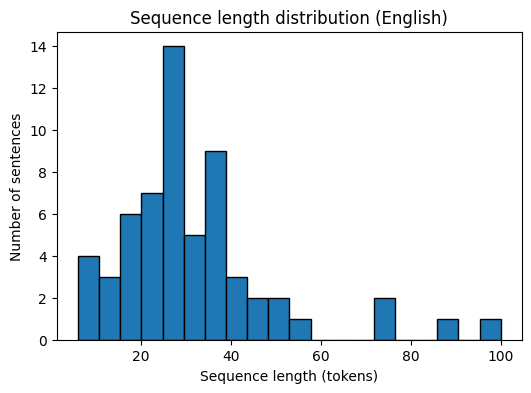

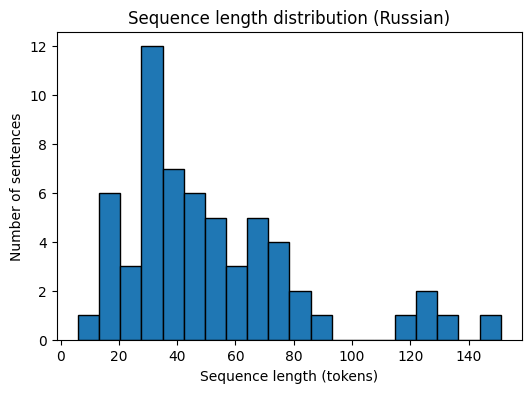

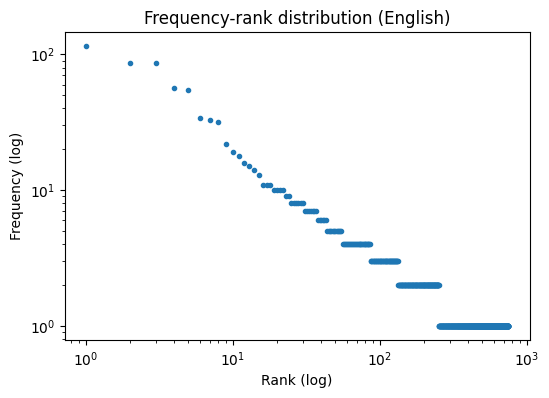

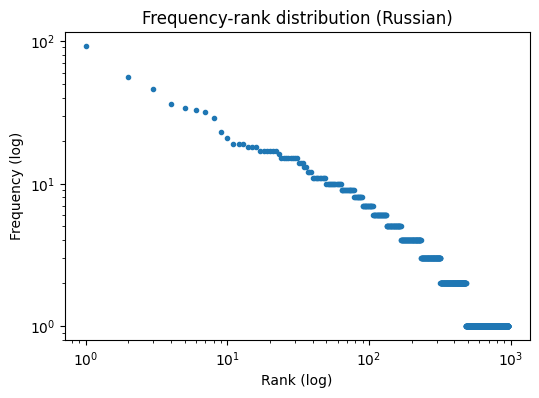

In [15]:
en_length_dist = sequence_length_distribution(english_sentences, "(English)")
ru_length_dist = sequence_length_distribution(russian_sentences, "(Russian)")

en_freq_dist = frequency_rank_distribution(english_sentences, "(English)")
ru_freq_dist = frequency_rank_distribution(russian_sentences, "(Russian)")

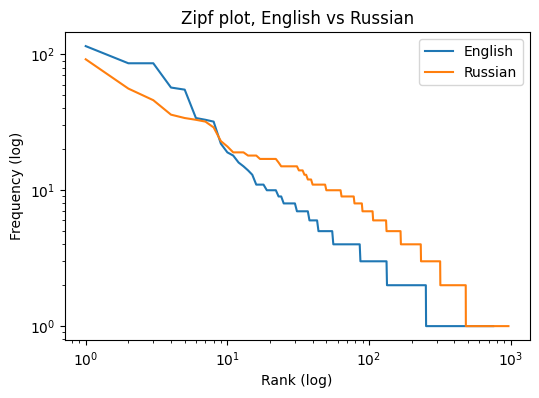

In [16]:
plt.figure(figsize=(6, 4))
for name, c in [("English", en_freq_dist), ("Russian", ru_freq_dist)]:
    f = sorted(c.values(), reverse=True)
    plt.loglog(range(1, len(f) + 1), f, label=name)
plt.xlabel("Rank (log)"); plt.ylabel("Frequency (log)"); plt.legend()
plt.title("Zipf plot, English vs Russian")
plt.show()

Implement a function that uses ancestral sampling on top of p(* | prefix) to generate sequences. This function should also be able to use the temperature parameter of p(* | prefix).

For all four `generate_sequence*` functions, `max_length` is the number of new
tokens, excluding the prefix. Generate exactly that many tokens, including any
sampled EOS tokens; do not stop early at EOS. Return only the continuation and
exclude the prefix from its frequency counts. Use a consistent return representation
across your samplers and retain the generated token boundaries for the counts.


In [17]:
@torch.inference_mode()
def generate_sequence(prefix: str, temperature: float, max_length: int):
    """Ancestral sampling. Returns a list of exactly max_length new token ids."""
    ids = str_to_tokens(prefix)
    out = model(input_ids=torch.tensor([ids], device=model.device), use_cache=True)
    past, logits = out.past_key_values, out.logits[0, -1].float()

    new_tokens = []
    for _ in range(max_length):
        if temperature == 0:
            nxt = logits.argmax().view(1)  # greedy
        else:
            probs = torch.softmax(logits / temperature, dim=-1)
            nxt = torch.multinomial(probs, 1)
        new_tokens.append(nxt.item())
        out = model(input_ids=nxt.view(1, 1), past_key_values=past, use_cache=True)
        past, logits = out.past_key_values, out.logits[0, -1].float()
    return new_tokens

Now use this function to sample 50 texts with max_length of 100 for each temperature value in {0, 0.7, 1, 1.2} using the prefix "hello" and compare their vocabulary distributions.

★ Why might temperature result in the observed differences?
- $T<1$ sharpens the softmax, so probability mass piles onto a few top tokens: a small vocabulary with many repeats. $T=0$ is fully greedy and deterministic. $T>1$ flattens the softmax, so rare tokens get sampled more often: more unique tokens, a longer tail, and eventually less coherent text.

In [18]:
from tqdm.auto import tqdm

def vocab_counts(seqs):
    c = Counter()
    for seq in seqs:
        for t in seq:
            c[tokens_to_str([t])] += 1
    return dict(c)

vocab_dist_per_temp = {}
# T=0 is deterministic: generate once, multiply counts by 50
seq = generate_sequence("hello", 0.0, 100)
vocab_dist_per_temp[0.0] = {k: v * 50 for k, v in vocab_counts([seq]).items()}
for T in [0.7, 1.0, 1.2]:
    seqs = [generate_sequence("hello", T, 100) for _ in tqdm(range(50), desc=f"T={T}")]
    vocab_dist_per_temp[T] = vocab_counts(seqs)

with open("results/vocab_distributions_per_temp.json", "w") as f:
    json.dump(vocab_dist_per_temp, f)

T=0.7:   0%|          | 0/50 [00:00<?, ?it/s]

T=1.0:   0%|          | 0/50 [00:00<?, ?it/s]

T=1.2:   0%|          | 0/50 [00:00<?, ?it/s]

Implement a function that modifies and renormalizes p(* | prefix) for ϵ-sampling.

If no token meets the epsilon threshold, use the original distribution without
filtering for that step. Use the same length and prefix conventions as the other
sampling functions.


In [19]:
@torch.inference_mode()
def generate_sequence_epsilon(prefix: str, temperature: float, epsilon: float, max_length: int):
    """Epsilon sampling. Returns a list of exactly max_length new token ids."""
    ids = str_to_tokens(prefix)
    out = model(input_ids=torch.tensor([ids], device=model.device), use_cache=True)
    past, logits = out.past_key_values, out.logits[0, -1].float()

    new_tokens = []
    for _ in range(max_length):
        if temperature == 0:
            nxt = logits.argmax().view(1)  # greedy
        else:
            probs = torch.softmax(logits / temperature, dim=-1)
            mask = probs >= epsilon
            if mask.any():  # otherwise keep the original distribution
                probs = probs * mask
                probs = probs / probs.sum()
            nxt = torch.multinomial(probs, 1)
        new_tokens.append(nxt.item())
        out = model(input_ids=nxt.view(1, 1), past_key_values=past, use_cache=True)
        past, logits = out.past_key_values, out.logits[0, -1].float()
    return new_tokens

Report Use ancestral sampling with temperature = 1 and ϵ in {0, 0.05, 0.1} to sample 50 texts of max length 100 for each value of ϵ using the prefix "hello", and compare their vocabulary distributions.

★ Why might ϵ result in the observed differences?
- Epsilon sampling truncates the tail: any token with probability below $\epsilon$ is removed and the rest is renormalized. Larger $\epsilon$ cuts more of the long tail of unlikely tokens, so the vocabulary gets smaller, rare or junk tokens disappear, and the text becomes more repetitive and coherent. At $\epsilon=0$ the full tail stays, giving the largest and most diverse vocabulary.

In [20]:
vocab_dist_per_epsilon = {}
for eps in [0.0, 0.05, 0.1]:
    seqs = [generate_sequence_epsilon("hello", 1.0, eps, 100)
            for _ in tqdm(range(50), desc=f"eps={eps}")]
    vocab_dist_per_epsilon[eps] = vocab_counts(seqs)

with open("results/vocab_distributions_per_epsilon.json", "w") as f:
    json.dump(vocab_dist_per_epsilon, f)

eps=0.0:   0%|          | 0/50 [00:00<?, ?it/s]

eps=0.05:   0%|          | 0/50 [00:00<?, ?it/s]

eps=0.1:   0%|          | 0/50 [00:00<?, ?it/s]

Implement a function that modifies and renormalizes p(* | prefix) for top-k sampling.

In [21]:
@torch.inference_mode()
def generate_sequence_top_k(prefix: str, temperature: float, top_k: int, max_length: int):
    """Top-k sampling. Returns a list of exactly max_length new token ids."""
    ids = str_to_tokens(prefix)
    out = model(input_ids=torch.tensor([ids], device=model.device), use_cache=True)
    past, logits = out.past_key_values, out.logits[0, -1].float()

    new_tokens = []
    for _ in range(max_length):
        if temperature == 0:
            nxt = logits.argmax().view(1)  # greedy
        else:
            probs = torch.softmax(logits / temperature, dim=-1)
            _, order = torch.sort(probs, descending=True)  # no torch.topk
            mask = torch.zeros_like(probs, dtype=torch.bool)
            mask[order[:top_k]] = True
            probs = probs * mask
            probs = probs / probs.sum()
            nxt = torch.multinomial(probs, 1)
        new_tokens.append(nxt.item())
        out = model(input_ids=nxt.view(1, 1), past_key_values=past, use_cache=True)
        past, logits = out.past_key_values, out.logits[0, -1].float()
    return new_tokens

Report Use ancestral sampling with temperature = 1 and k in {1, 20, 100} to sample 50 texts with max_length 100 tokens for each value of k with the prefix "hello", and compare their vocabulary distributions.

★ Why might k result in the observed differences?
- Top-k keeps only the $k$ most likely tokens at each step and renormalizes. A small $k$ forces the model onto its few best choices, giving a small, repetitive vocabulary ($k=1$ is deterministic). A larger $k$ lets more of the tail through, so the vocabulary grows and the text becomes more diverse but less reliable. Unlike epsilon sampling, $k$ is a fixed cutoff that ignores how peaked the distribution is: when the model is confident, $k=100$ still admits many tokens that are very unlikely, and when it is uncertain, $k=20$ may cut off reasonable options.

In [22]:
vocab_dist_per_k = {}
for k in [1, 20, 100]:
    seqs = [generate_sequence_top_k("hello", 1.0, k, 100)
            for _ in tqdm(range(50), desc=f"k={k}")]
    vocab_dist_per_k[k] = vocab_counts(seqs)

with open("results/vocab_distributions_per_k.json", "w") as f:
    json.dump(vocab_dist_per_k, f)

k=1:   0%|          | 0/50 [00:00<?, ?it/s]

k=20:   0%|          | 0/50 [00:00<?, ?it/s]

k=100:   0%|          | 0/50 [00:00<?, ?it/s]

Implement a function that modifies and renormalizes p(* | prefix) for top-p (nucleus) sampling.

In [23]:
@torch.inference_mode()
def generate_sequence_top_p(prefix: str, temperature: float, top_p: float, max_length: int):
    """Top-p (nucleus) sampling. Returns a list of exactly max_length new token ids."""
    ids = str_to_tokens(prefix)
    out = model(input_ids=torch.tensor([ids], device=model.device), use_cache=True)
    past, logits = out.past_key_values, out.logits[0, -1].float()

    new_tokens = []
    for _ in range(max_length):
        if temperature == 0:
            nxt = logits.argmax().view(1)  # greedy
        else:
            probs = torch.softmax(logits / temperature, dim=-1)
            sorted_p, order = torch.sort(probs, descending=True)
            # keep the smallest set of top tokens whose cumulative mass reaches top_p
            keep = (sorted_p.cumsum(0) - sorted_p) < top_p
            mask = torch.zeros_like(probs, dtype=torch.bool)
            mask[order[keep]] = True
            probs = probs * mask
            probs = probs / probs.sum()
            nxt = torch.multinomial(probs, 1)
        new_tokens.append(nxt.item())
        out = model(input_ids=nxt.view(1, 1), past_key_values=past, use_cache=True)
        past, logits = out.past_key_values, out.logits[0, -1].float()
    return new_tokens

Report Use ancestral sampling with temperature = 1 and p in {0.5, 0.9, 1.0} to sample 50 texts with max_length 100 for each value of p with the prefix "hello", and compare their length and vocabulary distributions.

★ Why might p result in the observed differences?
- Top-p keeps the smallest set of tokens whose probabilities sum to at least $p$, then renormalizes. A small $p$ (0.5) cuts the distribution down to the few dominant tokens, giving a small, repetitive vocabulary. $p=0.9$ trims only the unlikely tail, and $p=1.0$ keeps everything, giving the largest vocabulary with the most rare tokens. Unlike top-k, the cutoff adapts to the model’s confidence: when the distribution is peaked, few tokens are kept, and when it is flat, many are.

In [24]:
vocab_dist_per_p = {}
for p in [0.5, 0.9, 1.0]:
    seqs = [generate_sequence_top_p("hello", 1.0, p, 100)
            for _ in tqdm(range(50), desc=f"p={p}")]
    vocab_dist_per_p[p] = vocab_counts(seqs)
    n_unique = len(vocab_dist_per_p[p])
    print(f"p={p}: unique tokens = {n_unique}, total = {sum(vocab_dist_per_p[p].values())}")

with open("results/vocab_distributions_per_p.json", "w") as f:
    json.dump(vocab_dist_per_p, f)

p=0.5:   0%|          | 0/50 [00:00<?, ?it/s]

p=0.5: unique tokens = 881, total = 5000


p=0.9:   0%|          | 0/50 [00:00<?, ?it/s]

p=0.9: unique tokens = 1564, total = 5000


p=1.0:   0%|          | 0/50 [00:00<?, ?it/s]

p=1.0: unique tokens = 1912, total = 5000


# 2. Implementing sequence models (25 Points)

The validation perplexities below are targets for checking model performance.
Autograder feedback on exported predictions is not a measurement of those
perplexities; report your achieved validation values in `report.pdf`.


### 2.0 Setup

In [25]:
# Part 1 is complete; release its GPU memory before training the remaining models.
import gc
if "model" in globals():
    del model
gc.collect()
torch.cuda.empty_cache()


In [26]:
# This block handles basic setup and data loading using HuggingFace datasets.

# imports
from collections import defaultdict, Counter
import numpy as np
import math
import tqdm
import random
import pdb

import torch
from torch import nn
import torch.nn.functional as F
from datasets import load_dataset

# Load WikiText2 from HuggingFace
print("Loading WikiText2 dataset from HuggingFace (Salesforce/wikitext)...")
wikitext2 = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1")

# Process the data to create token lists
def process_wikitext_split(split_data):
    """Convert HuggingFace dataset split to list of tokens."""
    tokens = []
    for example in split_data:
        text = example['text'].strip()
        if text:  # Skip empty lines
            # Simple whitespace tokenization
            tokens.extend(text.split())
    return tokens

train_text = process_wikitext_split(wikitext2['train'])
validation_text = process_wikitext_split(wikitext2['validation'])
test_text = process_wikitext_split(wikitext2['test'])

# Build vocabulary from training data
print("Building vocabulary...")
word_counts = Counter(train_text)

# Create a vocab class to match torchtext interface
class SimpleVocab:
    def __init__(self, word_counts, special_tokens=['<unk>', '<eos>']):
        self.itos = special_tokens.copy()
        self.unk_index = 0  # Index of <unk> token (first special token)

        # Build initial stoi mapping
        _stoi = {token: idx for idx, token in enumerate(self.itos)}

        # Add all words from training data, sorted by frequency (most common first)
        for word, count in word_counts.most_common():
            if word not in _stoi:
                _stoi[word] = len(self.itos)
                self.itos.append(word)

        # Use defaultdict to return <unk> index for unknown words
        # This matches torchtext behavior where unknown words map to <unk>
        self.stoi = defaultdict(lambda: self.unk_index, _stoi)

    def __len__(self):
        return len(self.itos)

vocab = SimpleVocab(word_counts)
vocab_size = len(vocab)

print("Data loading complete!")
print("Number of words in the vocabulary: {}".format(vocab_size))
print("Number of tokens in training set: {}".format(len(train_text)))
print("Number of tokens in validation set: {}".format(len(validation_text)))
print("Number of tokens in test set: {}".format(len(test_text)))
print("Example text: {}".format(validation_text[:30]))

Loading WikiText2 dataset from HuggingFace (Salesforce/wikitext)...


README.md: 0.00B [00:00, ?B/s]

wikitext-2-raw-v1/test-00000-of-00001.pa(…):   0%|          | 0.00/733k [00:00<?, ?B/s]

wikitext-2-raw-v1/train-00000-of-00001.p(…):   0%|          | 0.00/6.36M [00:00<?, ?B/s]

wikitext-2-raw-v1/validation-00000-of-00(…):   0%|          | 0.00/657k [00:00<?, ?B/s]

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

Building vocabulary...
Data loading complete!
Number of words in the vocabulary: 76618
Number of tokens in training set: 2051910
Number of tokens in validation set: 213886
Number of tokens in test set: 241211
Example text: ['=', 'Homarus', 'gammarus', '=', 'Homarus', 'gammarus', ',', 'known', 'as', 'the', 'European', 'lobster', 'or', 'common', 'lobster', ',', 'is', 'a', 'species', 'of', 'clawed', 'lobster', 'from', 'the', 'eastern', 'Atlantic', 'Ocean', ',', 'Mediterranean', 'Sea']


We've implemented a unigram model here as a demonstration.

In [27]:
class UnigramModel:
    def __init__(self, train_text):
        self.counts = Counter(train_text)
        self.total_count = len(train_text)

    def probability(self, word):
        return self.counts[word] / self.total_count

    def next_word_probabilities(self, text_prefix):
        """Return a list of probabilities for each word in the vocabulary."""
        return [self.probability(word) for word in vocab.itos]

    def perplexity(self, full_text):
        """Return the perplexity of the model on a text as a float.

        full_text -- a list of string tokens
        """
        log_probabilities = []
        for word in full_text:
            # Note that the base of the log doesn't matter
            # as long as the log and exp use the same base.
            log_probabilities.append(math.log(max(self.probability(word), 1e-8), 2))
        return 2 ** -np.mean(log_probabilities)

unigram_demonstration_model = UnigramModel(train_text)
print('unigram validation perplexity:',
      unigram_demonstration_model.perplexity(validation_text))

def check_validity(model):
    """Performs several sanity checks on your model:
    1) That next_word_probabilities returns a valid distribution
    2) That perplexity matches a perplexity calculated from next_word_probabilities

    Although it is possible to calculate perplexity from next_word_probabilities,
    it is still good to have a separate more efficient method that only computes
    the probabilities of observed words.
    """

    log_probabilities = []
    for i in range(10):
        prefix = validation_text[:i]
        probs = model.next_word_probabilities(prefix)
        assert min(probs) >= 0, "Negative value in next_word_probabilities"
        assert max(probs) <= 1 + 1e-8, "Value larger than 1 in next_word_probabilities"
        assert abs(sum(probs)-1) < 1e-4, "next_word_probabilities do not sum to 1"

        word_id = vocab.stoi[validation_text[i]]
        selected_prob = probs[word_id]
        log_probabilities.append(math.log(selected_prob))

    perplexity = math.exp(-np.mean(log_probabilities))
    your_perplexity = model.perplexity(validation_text[:10])
    assert math.isclose(perplexity, your_perplexity, rel_tol=1e-5, abs_tol=0.1), "your perplexity does not " + \
    "match the one we calculated from `next_word_probabilities`,\n" + \
    "at least one of `perplexity` or `next_word_probabilities` is incorrect.\n" + \
    f"we calcuated {perplexity} from `next_word_probabilities`,\n" + \
    f"but your perplexity function returned {your_perplexity} (on a small sample)."


check_validity(unigram_demonstration_model)


unigram validation perplexity: 2051.6368254004396


To generate from the model, we can sample one word at a time conditioning on the words we have generated so far, just like how we did in the previous part.

In [28]:
# Note: the prefix tokens will be used by our trigram language model
def generate_text(model, n=20, prefix=('<eos>', '<eos>')):
    prefix = list(prefix)
    for _ in range(n):
        probs = model.next_word_probabilities(prefix)
        word = random.choices(vocab.itos, probs)[0]
        prefix.append(word)
    return ' '.join(prefix)

print(generate_text(unigram_demonstration_model))

<eos> <eos> political Ethiopia was on of titled show violent turning 2001 artists the at with was over sites and rear to


You will need to submit some outputs from the models you implement for us to grade. The following function will be used to generate the required output files.

In [29]:
from pathlib import Path
import urllib.request

for filename in ("eval_prefixes.txt", "eval_output_vocab.txt",
                 "eval_prefixes_short.txt", "eval_output_vocab_short.txt"):
    if not Path(filename).exists():
        bundled = source_dir / "data" / filename
        if bundled.exists():
            shutil.copy2(bundled, filename)
        else:
            urllib.request.urlretrieve(
                "https://cal-cs288.github.io/sp21/project_files/proj_1/" + filename, filename)

def save_truncated_distribution(model, filename, short=True):
    """Generate a file of truncated distributions.

    Probability distributions over the full vocabulary are large,
    so we will truncate the distribution to a smaller vocabulary.

    Please do not edit this function
    """
    vocab_name = 'eval_output_vocab'
    prefixes_name = 'eval_prefixes'

    if short:
      vocab_name += '_short'
      prefixes_name += '_short'

    with open('{}.txt'.format(vocab_name), 'r') as eval_vocab_file:
        eval_vocab = [w.strip() for w in eval_vocab_file]
    eval_vocab_ids = [vocab.stoi[s] for s in eval_vocab]

    all_selected_probabilities = []
    with open('{}.txt'.format(prefixes_name), 'r') as eval_prefixes_file:
        lines = eval_prefixes_file.readlines()
        for line in tqdm.tqdm_notebook(lines, leave=False):
            prefix = line.strip().split(' ')
            probs = model.next_word_probabilities(prefix)
            selected_probs = np.array([probs[i] for i in eval_vocab_ids], dtype=np.float32)
            all_selected_probabilities.append(selected_probs)

    all_selected_probabilities = np.stack(all_selected_probabilities)
    np.save(filename, all_selected_probabilities)
    print('saved', filename)


In [30]:
save_truncated_distribution(unigram_demonstration_model, 'results/unigram_demonstration_predictions.npy')

/tmp/ipykernel_1180/838180196.py:36: TqdmDeprecationWarning: This function will be removed in tqdm==5.0.0
Please use `tqdm.notebook.tqdm` instead of `tqdm.tqdm_notebook`
  for line in tqdm.tqdm_notebook(lines, leave=False):


  0%|          | 0/1000 [00:00<?, ?it/s]

saved results/unigram_demonstration_predictions.npy


### 2.1 N-gram Model (5 Points)

Now it's time to implement an n-gram language model.

Because not every n-gram will have been observed in training, use add-alpha smoothing to make sure no output word has probability 0.

$$P(w_2|w_1)=\frac{C(w_1,w_2)+\alpha}{C(w_1)+\alpha\cdot|V|}$$

where $|V|$ is the vocab size and $C$ is the count for the given bigram.  An alpha value around `3e-3`  should work.  Later, we'll replace this smoothing with model backoff. One edge case you will need to handle is at the beginning of the text where you don't have `n-1` prior words.  You can handle this however you like as long as you produce a valid probability distribution, but just using a uniform distribution over the vocabulary is reasonable for the purposes of this project.

A properly implemented bi-gram model should get a perplexity below 1500 on the validation set. Please note that the trigram model will probably have a very high perplexity at this point, due to sparsity issues. We'll correct this below.

**Note**: Do not change the signature of the `next_word_probabilities` and `perplexity` functions.  We will use these as a common interface for all of the different model types.  Make sure these two functions call `n_gram_probability`, because later we are going to override `n_gram_probability` in a subclass.
Also, we suggest pre-computing and caching the counts $C$ when you initialize `NGramModel` for efficiency.

In [31]:
class NGramModel:
    def __init__(self, train_text, n=2, alpha=3e-3):
        self.n = n
        self.smoothing = alpha
        self.V = len(vocab.itos)

        # ngram_counts[(w1, ..., wn)] = C(w1..wn)
        # context_counts[(w1, ..., w_{n-1})] = C(w1..w_{n-1}) as a context followed by a word
        # For n=1 the context is the empty tuple, so its count is the number of tokens.
        self.ngram_counts = Counter()
        self.context_counts = Counter()
        for i in range(len(train_text) - n + 1):
            ngram = tuple(train_text[i:i + n])
            self.ngram_counts[ngram] += 1
            self.context_counts[ngram[:-1]] += 1

    def n_gram_probability(self, n_gram):
        """Return P(last word | previous n-1 words) with add-alpha smoothing."""
        assert len(n_gram) == self.n
        n_gram = tuple(n_gram)
        num = self.ngram_counts[n_gram] + self.smoothing
        den = self.context_counts[n_gram[:-1]] + self.smoothing * self.V
        return num / den

    def next_word_probabilities(self, text_prefix):
        """Return a list of probabilities for each word in the vocabulary."""
        prefix = list(text_prefix)
        if len(prefix) < self.n - 1:
            # not enough context: uniform distribution
            return [1.0 / self.V] * self.V
        context = prefix[len(prefix) - (self.n - 1):]  # last n-1 words (empty for n=1)
        return [self.n_gram_probability(context + [w]) for w in vocab.itos]

    def perplexity(self, full_text):
        """full_text is a list of string tokens."""
        log_prob_sum = 0.0
        for i in range(len(full_text)):
            if i < self.n - 1:
                p = 1.0 / self.V  # same uniform convention as next_word_probabilities
            else:
                p = self.n_gram_probability(full_text[i - self.n + 1:i + 1])
            log_prob_sum += math.log(p)
        return math.exp(-log_prob_sum / len(full_text))

unigram_model = NGramModel(train_text, 1)
check_validity(unigram_model)
bigram_model = NGramModel(train_text, n=2)
check_validity(bigram_model)
print('bigram validation perplexity:', bigram_model.perplexity(validation_text))
trigram_model = NGramModel(train_text, n=3)
check_validity(trigram_model)
save_truncated_distribution(bigram_model, 'results/bigram_predictions.npy')

bigram validation perplexity: 1448.8367175110927


/tmp/ipykernel_1180/838180196.py:36: TqdmDeprecationWarning: This function will be removed in tqdm==5.0.0
Please use `tqdm.notebook.tqdm` instead of `tqdm.tqdm_notebook`
  for line in tqdm.tqdm_notebook(lines, leave=False):


  0%|          | 0/1000 [00:00<?, ?it/s]

saved results/bigram_predictions.npy


Please download `bigram_predictions.npy` once you finish this section so that you can submit it.

Report your bigram validation perplexity in `report.pdf`.  (We will use this to help us calibrate our scoring on the test set.)

<!-- Do not remove this comment, it is used by the autograder: RqYJKsoTS6 -->

Include in `report.pdf`:

* Bigram validation perplexity.

We can also generate samples from the model to get an idea of how it is doing.

In [32]:
print(generate_text(bigram_model))

<eos> <eos> Winterburn Ordinance desertion Perichromatin fronted Paddan port GN virus Gobrecht Videos disagreement trade with it up even for replacement for


We now free up some RAM, **it is important to run the cell below, otherwise you will likely run out of RAM in the Colab runtime.**

In [33]:
# Free up some RAM.
del bigram_model
del trigram_model

### 2.2 N-gram Backoff (5 Points)

This basic model works okay for bigrams, but a better strategy (especially for higher-order models) is to use backoff.  Implement backoff with absolute discounting:
$$
\begin{align}
P\left(w_i|w_{i-n+1}^{i-1}\right)&=\frac{max\left\{C(w_{i-n+1}^i)-\delta,0\right\}}{\sum_{w_i} C\left(w_{i-n+1}^i\right)} + \alpha\left(w_{i-n+1}^{i-1}\right) P\left(w_i|w_{i-n+2}^{i-1}\right) \\
\alpha\left(w_{i-n+1}^{i-1}\right)&=\frac{\delta N_{1+}\left(w_{i-n+1}^{i-1}\right)}{{\sum_{w_i} C\left(w_{i-n+1}^i\right)}}
\end{align}
$$
where $N_{1+}$ is the number of words that appear after the previous $n-1$ words (the number of times the max will select something other than 0 in the first equation).  If $\sum_{w_i} C(w_{i-n+1}^i)=0$, use the lower order model probability directly (the above equations would have a division by 0). We found a discount $\delta$ of 0.9 to work well based on validation performance.  A trigram model with this discount value should get a validation perplexity below 700.

In [ ]:
class DiscountBackoffModel(NGramModel):
    def __init__(self, train_text, lower_order_model, n=2, delta=0.9):
        super().__init__(train_text, n=n)
        self.lower_order_model = lower_order_model
        self.discount = delta
        self.followers = Counter()
        for ngram in self.ngram_counts:
            self.followers[ngram[:-1]] += 1

    def n_gram_probability(self, n_gram):
        assert len(n_gram) == self.n
        n_gram = tuple(n_gram)
        context = n_gram[:-1]
        lower = self.lower_order_model.n_gram_probability(n_gram[1:])
        total = self.context_counts[context]
        if total == 0:
            return lower
        alpha = self.discount * self.followers[context] / total
        return max(self.ngram_counts[n_gram] - self.discount, 0) / total + alpha * lower


bigram_backoff_model = DiscountBackoffModel(train_text, unigram_model, 2)
trigram_backoff_model = DiscountBackoffModel(train_text, bigram_backoff_model, 3)
check_validity(trigram_backoff_model)
print('trigram backoff validation perplexity:', trigram_backoff_model.perplexity(validation_text))

save_truncated_distribution(trigram_backoff_model, 'results/discount_backoff_predictions.npy') # this might take a few minutes

trigram backoff validation perplexity: 678.4869796067352


/tmp/ipykernel_1180/838180196.py:36: TqdmDeprecationWarning: This function will be removed in tqdm==5.0.0
Please use `tqdm.notebook.tqdm` instead of `tqdm.tqdm_notebook`
  for line in tqdm.tqdm_notebook(lines, leave=False):


  0%|          | 0/1000 [00:00<?, ?it/s]

Free up RAM.

In [ ]:
# Release models we don't need any more.
del unigram_model
del bigram_backoff_model
del trigram_backoff_model

### 2.3 Smoothed N-gram Model (5 Points)

Now, implement Kneser-Ney to replace the unigram base model.
$$P(w)\propto |\{w':c(w',w) > 0\}|$$
A Kneser-Ney trigram model should get a validation perplexity below 675.

In [ ]:
class KneserNeyBaseModel(NGramModel):
    def __init__(self, train_text):
        super().__init__(train_text, n=1)

        # Continuation count of w: number of distinct words w' that precede w
        bigram_types = set(zip(train_text[:-1], train_text[1:]))
        self.continuation_counts = Counter(w for _, w in bigram_types)
        self.total_continuations = len(bigram_types)  # number of distinct bigram types

    def n_gram_probability(self, n_gram):
        assert len(n_gram) == 1
        w = n_gram[0]
        # P(w) proportional to |{w' : c(w', w) > 0}|, with a tiny add-alpha so unseen words
        # (e.g. <unk>, <eos>, or the first training word) never get probability 0
        num = self.continuation_counts[w] + self.smoothing
        den = self.total_continuations + self.smoothing * self.V
        return num / den

kn_base = KneserNeyBaseModel(train_text)
check_validity(kn_base)
bigram_kn_backoff_model = DiscountBackoffModel(train_text, kn_base, 2)
trigram_kn_backoff_model = DiscountBackoffModel(train_text, bigram_kn_backoff_model, 3)
print('trigram Kneser-Ney backoff validation perplexity:', trigram_kn_backoff_model.perplexity(validation_text))

save_truncated_distribution(trigram_kn_backoff_model, 'results/trigram_kn_predictions.npy') # this might take a few minutes

In [ ]:
print(generate_text(trigram_kn_backoff_model))
print(generate_text(trigram_kn_backoff_model, prefix=['What','about']))

Report your trigram backoff perplexities with and without Kneser Ney in `report.pdf`.

<!-- Do not remove this comment, it is used by the autograder: RqYJKsoTS6 -->

Include in `report.pdf`:

* Trigram backoff validation perplexity.
* Trigram backoff with Kneser Ney perplexity.

Free up RAM.

In [ ]:
# Delete models we don't need.
del kn_base
del bigram_kn_backoff_model
del trigram_kn_backoff_model

If you want to learn more about n-gram language models and smoothing techniques, checkout the following paper: https://people.eecs.berkeley.edu/~klein/cs294-5/chen_goodman.pdf

### 2.4 Neural N-gram Model (5 Points)

In this section, you will implement a neural version of an n-gram model.  The model will use a simple feedforward neural network that takes the previous `n-1` words and outputs a distribution over the next word.

You will use PyTorch to implement the model.  We've provided a little bit of code to help with the data loading using PyTorch's data loaders (https://pytorch.org/docs/stable/data.html)

Use a validation perplexity below 550 as the target for the following suggested architecture and hyperparameters.
* embed the words with dimension 128, then flatten into a single embedding for $n-1$ words (with size $(n-1)*128$)
* run 2 hidden layers with 1024 hidden units, then project down to size 128 before the final layer (ie. 4 layers total).
* use weight tying for the embedding and final linear layer (this made a very large difference in our experiments); you can do this by creating the output layer with `nn.Linear`, then using `F.embedding` with the linear layer's `.weight` to embed the input
* rectified linear activation (ReLU) and dropout 0.1 after first 2 hidden layers. **Note: You will likely find a performance drop if you add a nonlinear activation function after the dimension reduction layer.**
* train for 10 epochs with the Adam optimizer (should take around 15-20 minutes)
* do early stopping based on validation set perplexity (see HW1A)


We encourage you to try other architectures and hyperparameters, and you will likely find some that work better than the ones listed above.  Report your achieved validation perplexity, including when it is above the target.

In [ ]:
import copy

def ids(tokens):
    return [vocab.stoi[t] for t in tokens]

class NeuralNgramDataset(torch.utils.data.Dataset):
    def __init__(self, text_token_ids, n):
        self.text_token_ids = text_token_ids
        self.n = n
    def __len__(self):
        return len(self.text_token_ids)
    def __getitem__(self, i):
        if i < self.n-1:
            prev = [vocab.stoi['<eos>']] * (self.n-i-1) + self.text_token_ids[:i]
        else:
            prev = self.text_token_ids[i-self.n+1:i]
        return torch.tensor(prev), torch.tensor(self.text_token_ids[i])

class NeuralNGramNetwork(nn.Module):
    def __init__(self, n):
        super().__init__()
        self.n = n
        self.emb_dim = 128
        self.fc1 = nn.Linear((n - 1) * self.emb_dim, 1024)
        self.fc2 = nn.Linear(1024, 1024)
        self.fc3 = nn.Linear(1024, self.emb_dim)   # reduction layer, no nonlinearity after it
        self.dropout = nn.Dropout(0.1)
        self.out = nn.Linear(self.emb_dim, vocab_size)  # its weight also serves as the embedding

    def forward(self, x):
        # x: (batch, n-1) token ids -> (batch, vocab_size) log probabilities
        emb = F.embedding(x, self.out.weight)        # (batch, n-1, 128), weight tying
        h = emb.reshape(x.size(0), -1)               # (batch, (n-1)*128)
        h = self.dropout(F.relu(self.fc1(h)))
        h = self.dropout(F.relu(self.fc2(h)))
        h = self.fc3(h)                              # (batch, 128)
        return F.log_softmax(self.out(h), dim=-1)

class NeuralNGramModel:
    def __init__(self, n):
        self.n = n
        self.network = NeuralNGramNetwork(n).cuda()

    def train(self, epochs=10, batch_size=128, lr=1e-3):
        dataset = NeuralNgramDataset(ids(train_text), self.n)
        train_loader = torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=True)
        optimizer = torch.optim.Adam(self.network.parameters(), lr=lr)

        best_ppl, best_state = float("inf"), None
        for epoch in range(epochs):
            self.network.train()
            total_loss = 0.0
            pbar = tqdm.tqdm(train_loader, desc=f"epoch {epoch + 1}/{epochs}", leave=False)
            for i, (x, y) in enumerate(pbar, start=1):
                x, y = x.cuda(), y.cuda()
                optimizer.zero_grad()
                loss = F.nll_loss(self.network(x), y)
                loss.backward()
                optimizer.step()
                total_loss += loss.item()
                if i % 50 == 0:
                    pbar.set_postfix(loss=total_loss / i)

            val_ppl = self.perplexity(validation_text)
            print(f"epoch {epoch + 1}: train loss {total_loss / i:.3f}, val perplexity {val_ppl:.1f}")
            if val_ppl < best_ppl:  # early stopping: keep the best checkpoint
                best_ppl = val_ppl
                best_state = copy.deepcopy(self.network.state_dict())

        self.network.load_state_dict(best_state)
        print(f"loaded best checkpoint, val perplexity {best_ppl:.1f}")

    @torch.no_grad()
    def next_word_probabilities(self, text_prefix):
        self.network.eval()
        prev = ids(list(text_prefix))
        prev = prev[len(prev) - (self.n - 1):]  # last n-1 ids (safe for short prefixes)
        # pad with <eos> at the front, same as NeuralNgramDataset
        prev = [vocab.stoi['<eos>']] * (self.n - 1 - len(prev)) + prev
        x = torch.tensor([prev]).cuda()
        return self.network(x)[0].exp().cpu().tolist()

    @torch.no_grad()
    def perplexity(self, text):
        self.network.eval()
        dataset = NeuralNgramDataset(ids(text), self.n)
        loader = torch.utils.data.DataLoader(dataset, batch_size=1024, shuffle=False)
        total_nll, count = 0.0, 0
        for x, y in loader:
            x, y = x.cuda(), y.cuda()
            total_nll += F.nll_loss(self.network(x), y, reduction="sum").item()
            count += y.numel()
        return math.exp(total_nll / count)

neural_trigram_model = NeuralNGramModel(3)
check_validity(neural_trigram_model)
neural_trigram_model.train()
print('neural trigram validation perplexity:', neural_trigram_model.perplexity(validation_text))
save_truncated_distribution(neural_trigram_model, 'results/neural_trigram_predictions.npy', short=False)

Report your neural trigram perplexity in `report.pdf`.

<!-- Do not remove this comment, it is used by the autograder: RqYJKsoTS6 -->

Include in `report.pdf`:

* Neural trigram validation perplexity.

Free up RAM.

In [ ]:
# Delete model we don't need.
del neural_trigram_model

### 2.5 LSTM Model (5 Points)

For this stage of the project, you will implement an LSTM language model.

For recurrent language modeling, the data batching strategy is a bit different from what is used in some other tasks.  Sentences are concatenated together so that one sentence starts right after the other, and an unfinished sentence will be continued in the next batch.  The provided `BPTTIterator` below manages this batching with the same interface.  To properly deal with this input format, you should save the last state of the LSTM from a batch to feed in as the first state of the next batch.  When you save state across different batches, you should call `.detach()` on the state tensors before the next batch to tell PyTorch not to backpropagate gradients through the state into the batch you have already finished (which will cause a runtime error).

Use a validation perplexity below 350 as your target. The following architecture and hyperparameters are suggested starting points.
* 3 LSTM layers with 512 units
* dropout of 0.5 after each LSTM layer
* instead of projecting directly from the last LSTM output to the vocabulary size for softmax, project down to a smaller size first (e.g. 512->128->vocab_size). **NOTE: You may find that adding nonlinearities between these layers can hurt performance, try without first.**
* use the same weights for the embedding layer and the pre-softmax layer; dimension 128
* train with Adam (using default learning rates) for at least 20 epochs


In [ ]:
# Create datasets for the LSTM model
# Since we're using a custom implementation, we need to create a BPTT iterator

class LanguageModelingDataset:
    """Simple dataset wrapper for language modeling."""
    def __init__(self, text_tokens):
        # Convert tokens to indices
        self.data = torch.tensor(ids(text_tokens), dtype=torch.long)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        return self.data[idx]

class BPTTIterator:
    """Custom BPTT (Backpropagation Through Time) iterator.

    This mimics the behavior of torchtext.data.BPTTIterator.
    """
    def __init__(self, dataset, batch_size, bptt_len, device):
        self.data = dataset.data.to(device)
        self.batch_size = batch_size
        self.bptt_len = bptt_len
        self.device = device

        # Calculate number of batches
        # We divide the data into batch_size chunks
        self.n_tokens = (len(self.data) // batch_size) * batch_size
        self.data = self.data[:self.n_tokens].view(batch_size, -1).t().contiguous()

    def __iter__(self):
        for i in range(0, self.data.size(0) - 1, self.bptt_len):
            seq_len = min(self.bptt_len, self.data.size(0) - 1 - i)
            # Create batch object with .text and .target attributes
            batch = type('obj', (object,), {
                'text': self.data[i:i+seq_len],
                'target': self.data[i+1:i+1+seq_len]
            })()
            yield batch

    def __len__(self):
        return (self.data.size(0) - 1 + self.bptt_len - 1) // self.bptt_len

# Create a namespace to mimic torchtext.data
class TorchtextData:
    BPTTIterator = BPTTIterator

class TorchtextNamespace:
    data = TorchtextData()

torchtext = TorchtextNamespace()

# Create datasets from the text data
print("Creating LSTM datasets...")
train_dataset = LanguageModelingDataset(train_text)
validation_dataset = LanguageModelingDataset(validation_text)
test_dataset = LanguageModelingDataset(test_text)
print(f"Train dataset size: {len(train_dataset)}")
print(f"Validation dataset size: {len(validation_dataset)}")
print(f"Test dataset size: {len(test_dataset)}")


In [ ]:
import copy

class LSTMNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb_dim = 128
        self.hidden = 512
        self.num_layers = 3
        self.embed = nn.Embedding(vocab_size, self.emb_dim)
        # dropout=0.5 applies between LSTM layers; the extra dropout below covers the last layer
        self.lstm = nn.LSTM(self.emb_dim, self.hidden, num_layers=self.num_layers, dropout=0.5)
        self.dropout = nn.Dropout(0.5)
        self.proj = nn.Linear(self.hidden, self.emb_dim)   # 512 -> 128, no nonlinearity
        self.out = nn.Linear(self.emb_dim, vocab_size)
        self.out.weight = self.embed.weight                # weight tying

    def init_state(self, batch_size):
        z = torch.zeros(self.num_layers, batch_size, self.hidden, device=next(self.parameters()).device)
        return (z, z.clone())

    def forward(self, x, state):
        # x: (seq_len, batch) -> log probs (seq_len, batch, vocab_size)
        h = self.embed(x)                       # (seq, batch, 128)
        h, state = self.lstm(h, state)          # (seq, batch, 512)
        h = self.dropout(h)
        h = self.proj(h)                        # (seq, batch, 128)
        return F.log_softmax(self.out(h), dim=-1), state

class LSTMModel:
    "A class that wraps LSTMNetwork to handle training and evaluation."

    def __init__(self):
        self.network = LSTMNetwork().cuda()

    def train(self, epochs=20, lr=1e-3, clip=1.0):
        train_iterator = torchtext.data.BPTTIterator(train_dataset, batch_size=64,
                                                     bptt_len=32, device='cuda')
        optimizer = torch.optim.Adam(self.network.parameters(), lr=lr)
        best_ppl, best_state = float("inf"), None

        for epoch in range(epochs):
            self.network.train()
            state = self.network.init_state(64)   # zero state at the start of each epoch
            total_loss, steps = 0.0, 0
            for batch in train_iterator:
                # detach so gradients do not flow into previous batches
                state = tuple(s.detach() for s in state)
                optimizer.zero_grad()
                log_probs, state = self.network(batch.text, state)
                loss = F.nll_loss(log_probs.reshape(-1, vocab_size), batch.target.reshape(-1))
                loss.backward()
                nn.utils.clip_grad_norm_(self.network.parameters(), clip)
                optimizer.step()
                total_loss += loss.item()
                steps += 1

            val_ppl = self.dataset_perplexity(validation_dataset)
            print(f"epoch {epoch + 1}/{epochs}: train loss {total_loss / steps:.3f}, val perplexity {val_ppl:.1f}")
            if val_ppl < best_ppl:  # keep the best checkpoint
                best_ppl = val_ppl
                best_state = copy.deepcopy(self.network.state_dict())

        self.network.load_state_dict(best_state)
        print(f"loaded best checkpoint, val perplexity {best_ppl:.1f}")

    @torch.no_grad()
    def next_word_probabilities(self, text_prefix):
        "Return a list of probabilities for each word in the vocabulary."
        self.network.eval()
        if len(text_prefix) == 0:
            text_prefix = ['<eos>']  # an LSTM needs at least one input token
        prefix_token_tensor = torch.tensor(ids(text_prefix), device='cuda').view(-1, 1)
        state = self.network.init_state(1)
        log_probs, _ = self.network(prefix_token_tensor, state)
        return log_probs[-1, 0].exp().cpu().tolist()

    @torch.no_grad()
    def dataset_perplexity(self, torchtext_dataset):
        "Return perplexity as a float."
        self.network.eval()
        iterator = torchtext.data.BPTTIterator(torchtext_dataset, batch_size=64, bptt_len=32, device='cuda')
        state = self.network.init_state(64)
        total_nll, count = 0.0, 0
        for batch in iterator:
            log_probs, state = self.network(batch.text, state)
            total_nll += F.nll_loss(log_probs.reshape(-1, vocab_size),
                                    batch.target.reshape(-1), reduction="sum").item()
            count += batch.target.numel()
        return math.exp(total_nll / count)

lstm_model = LSTMModel()
lstm_model.train()

print('lstm validation perplexity:', lstm_model.dataset_perplexity(validation_dataset))
save_truncated_distribution(lstm_model, 'results/lstm_predictions.npy', short=False)

# Save the LSTM model for use in section 3.1 (text classification with transfer learning)
print('\nSaving LSTM model checkpoint...')
torch.save(lstm_model.network.state_dict(), 'lstm_model.pt')
print('✓ Saved LSTM model to lstm_model.pt')

<!-- Do not remove this comment, it is used by the autograder: RqYJKsoTS6 -->

Report your LSTM validation perplexity in `report.pdf`.

In [ ]:
del lstm_model

# 3. Acquiring and using word and sentence representations (25 Points)

### 3.0 Setup

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from datasets import load_dataset
import numpy as np
from collections import Counter
import tqdm

# Load IMDB dataset
print("Loading IMDB dataset...")
imdb_dataset = load_dataset("imdb")
train_data = imdb_dataset['train']
test_data = imdb_dataset['test']

print(f"Train size: {len(train_data)}")
print(f"Test size: {len(test_data)}")
print(f"Example: {train_data[0]}")


### 3.1 Text classification (10 Points)

In this section we will use the LSTM model we trained in the previous section, to perform text classification. The hidden state of the LSTM contains rich semantic features about the text it is given. We can use this embedding of the hidden state to provide features for a classifier. Here we will perform sentiment classification, using the LSTM hidden state.

First we will load the lstm model trained in the previous section.

In [ ]:
# Load the LSTM language model from section 2 to use as a feature extractor
print("Loading pre-trained LSTM language model from section 2...")
lstm_feature_extractor = LSTMNetwork()
lstm_feature_extractor.load_state_dict(torch.load('lstm_model.pt', map_location='cpu'))
lstm_feature_extractor.eval()
device = 'cuda' if torch.cuda.is_available() else 'cpu'
lstm_feature_extractor = lstm_feature_extractor.to(device)
print(f"✓ Successfully loaded LSTM model on {device}")

# Function to convert IMDB text to WikiText2 vocab indices
def imdb_text_to_wikitext_tokens(text, wikitext_vocab, max_len=256):
    """Convert IMDB text to WikiText2 vocabulary token IDs."""
    # Preserve last fall's IMDB preprocessing: lowercase, then split on whitespace.
    words = text.lower().split()[:max_len]
    # Map to WikiText2 vocab (unknown words will map to <unk>)
    token_ids = [wikitext_vocab.stoi[word] for word in words]
    return token_ids


Now implement the following function, which should extract features from the LSTM given a list of texts. (HINT: you will have to convert the text into token ids using the same vocab as used to train the LSTM model.)

We will compare two different embeddings to use as features for our MLP classifier:

1) The mean of the final layer embeddings across all tokens in the sequence.
2) The last token final layer embedding.

In [ ]:
@torch.no_grad()
def extract_lstm_features(lstm_model, texts, wikitext_vocab, embedding_type='mean', batch_size=128):
    assert embedding_type in ('mean', 'last')
    lstm_model.eval()
    dev = next(lstm_model.parameters()).device
    unk = wikitext_vocab.stoi['<unk>']
    feats = []
    for start in tqdm.tqdm(range(0, len(texts), batch_size), desc=f"features ({embedding_type})", leave=False):
        batch_ids = [imdb_text_to_wikitext_tokens(t, wikitext_vocab) or [unk]
                     for t in texts[start:start + batch_size]]
        B, T = len(batch_ids), max(len(s) for s in batch_ids)
        lengths = torch.tensor([len(s) for s in batch_ids], device=dev)
        x = torch.zeros(T, B, dtype=torch.long)
        for j, s in enumerate(batch_ids):
            x[:len(s), j] = torch.tensor(s)
        x = x.to(dev)

        out, _ = lstm_model.lstm(lstm_model.embed(x))   # (T, B, 512), zero initial state
        if embedding_type == 'mean':
            mask = (torch.arange(T, device=dev)[:, None] < lengths[None, :]).unsqueeze(-1).float()
            f = (out * mask).sum(0) / lengths[:, None]   # mean over real tokens only
        else:
            f = out[lengths - 1, torch.arange(B, device=dev)]  # last real token
        feats.append(f.cpu())
    return torch.cat(feats)

In [ ]:
# Extract features if LSTM model is available
# Extract features for train and test sets
train_features_mean = extract_lstm_features(
    lstm_feature_extractor,
    train_data['text'],
    vocab,  # WikiText2 vocab from section 2
    embedding_type='mean'
)

train_features_last = extract_lstm_features(
    lstm_feature_extractor,
    train_data['text'],
    vocab,  # WikiText2 vocab from section 2
    embedding_type='last'
)

test_features_mean = extract_lstm_features(
    lstm_feature_extractor,
    test_data['text'],
    vocab,  # WikiText2 vocab from section 2
    embedding_type='mean'
)

test_features_last = extract_lstm_features(
    lstm_feature_extractor,
    test_data['text'],
    vocab,  # WikiText2 vocab from section 2
    embedding_type='last'
)

# Save features to disk for reuse
torch.save(train_features_mean, 'imdb_train_lstm_features_mean.pt')
torch.save(train_features_last, 'imdb_train_lstm_features_last.pt')
torch.save(test_features_mean, 'imdb_test_lstm_features_mean.pt')
torch.save(test_features_last, 'imdb_test_lstm_features_last.pt')


Now we will create dataloaders for each of our feature sets.

In [ ]:
# Create feature-based dataset
class IMDBFeatureDataset(Dataset):
    """Dataset that uses pre-extracted LSTM features."""
    def __init__(self, features, labels):
        self.features = features
        self.labels = torch.tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return self.features[idx], self.labels[idx]


# Create dataloaders with extracted features
train_dataset_mean = IMDBFeatureDataset(train_features_mean, train_data['label'])
test_dataset_mean = IMDBFeatureDataset(test_features_mean, test_data['label'])

train_dataset_last = IMDBFeatureDataset(train_features_last, train_data['label'])
test_dataset_last = IMDBFeatureDataset(test_features_last, test_data['label'])

train_loader_mean = DataLoader(train_dataset_mean, batch_size=64, shuffle=True)
test_loader_mean = DataLoader(test_dataset_mean, batch_size=64, shuffle=False)

train_loader_last = DataLoader(train_dataset_last, batch_size=64, shuffle=True)
test_loader_last = DataLoader(test_dataset_last, batch_size=64, shuffle=False)


Using these embeddings, train two MLP classifiers. One on the mean embeddings and one on the last embeddings.

Keep all five TODO methods in `MLPClassifier`. `forward(x)` takes a batch of
precomputed features. For `class_prediction`, you may accept either a review
string or one feature vector; document your choice and adjust its input annotation
if needed. It must return a single 0/1 label. `dataset_accuracy` takes a labeled
feature dataset or its DataLoader and returns the fraction classified correctly.

Create and train a separate classifier for each feature type. Fill the result
fields below using the supplied test split, with predictions in its original order.


In [ ]:
from sklearn.metrics import precision_recall_fscore_support, accuracy_score

class MLPClassifier(nn.Module):
    # Choose the feature type and training loader via attributes (defaults keep a no-arg call valid).
    def __init__(self, feature_type='mean', train_loader=None, in_dim=512):
        super().__init__()
        self.feature_type = feature_type
        self.train_loader = train_loader
        self.net = nn.Sequential(
            nn.Linear(in_dim, 256), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(256, 64), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(64, 2),
        )
        self.to(device)

    def forward(self, x):
        # x: (batch, in_dim) precomputed features -> (batch, 2) logits
        return self.net(x)

    def train(self, epochs=15, lr=1e-3):
        # Called as clf.train(). Toggle module mode with nn.Module.train(self, mode),
        # because nn.Module.eval() would call this custom train with an argument.
        optimizer = torch.optim.Adam(self.parameters(), lr=lr)
        for epoch in range(epochs):
            nn.Module.train(self, True)
            total, n = 0.0, 0
            for x, y in self.train_loader:
                x, y = x.to(device), y.to(device)
                optimizer.zero_grad()
                loss = F.cross_entropy(self(x), y)
                loss.backward()
                optimizer.step()
                total += loss.item() * len(y)
                n += len(y)
            print(f"{self.feature_type} epoch {epoch + 1}/{epochs}: loss {total / n:.4f}")
        nn.Module.train(self, False)

    @torch.no_grad()
    def class_prediction(self, text_prefix: str) -> int:
        # Input choice: a raw review STRING. It is featurized with the global
        # lstm_feature_extractor and WikiText vocab, using this classifier's feature_type.
        nn.Module.train(self, False)
        f = extract_lstm_features(lstm_feature_extractor, [text_prefix], vocab, self.feature_type).to(device)
        return int(self(f).argmax(dim=1).item())

    @torch.no_grad()
    def predict_dataset(self, dataset):
        nn.Module.train(self, False)
        loader = dataset if isinstance(dataset, DataLoader) else DataLoader(dataset, batch_size=256, shuffle=False)
        preds = []
        for x, _ in loader:
            preds.extend(self(x.to(device)).argmax(dim=1).cpu().tolist())
        return preds

    @torch.no_grad()
    def dataset_accuracy(self, dataset) -> float:
        loader = dataset if isinstance(dataset, DataLoader) else DataLoader(dataset, batch_size=256, shuffle=False)
        preds = self.predict_dataset(loader)
        labels = torch.cat([y for _, y in loader]).tolist()
        return sum(p == l for p, l in zip(preds, labels)) / len(labels)

★ Report the performance of each method using accuracy, precision, recall, and F1 score. Which method performs the best? Which performs the worst? Why?

In [ ]:
clf_mean = MLPClassifier(feature_type='mean', train_loader=train_loader_mean)
clf_mean.train()
clf_last = MLPClassifier(feature_type='last', train_loader=train_loader_last)
clf_last.train()

test_labels = imdb_dataset['test']['label']   # original test order

def metrics(clf, loader):
    preds = clf.predict_dataset(loader)          # loader has shuffle=False, so order is preserved
    p, r, f1, _ = precision_recall_fscore_support(test_labels, preds, average='binary', pos_label=1)
    return accuracy_score(test_labels, preds), p, r, f1, [int(x) for x in preds]

mean_emb_accuracy, mean_emb_precision, mean_emb_recall, mean_emb_f1, mean_predictions = metrics(clf_mean, test_loader_mean)
last_emb_accuracy, last_emb_precision, last_emb_recall, last_emb_f1, last_predictions = metrics(clf_last, test_loader_last)

print(f"mean: acc {mean_emb_accuracy:.4f} P {mean_emb_precision:.4f} R {mean_emb_recall:.4f} F1 {mean_emb_f1:.4f}")
print(f"last: acc {last_emb_accuracy:.4f} P {last_emb_precision:.4f} R {last_emb_recall:.4f} F1 {last_emb_f1:.4f}")

with open('results/imdb_lstm_classifier_results.json', 'w') as f:
    json.dump({
        'last_emb_accuracy': float(last_emb_accuracy), 'mean_emb_accuracy': float(mean_emb_accuracy),
        'last_emb_precision': float(last_emb_precision), 'mean_emb_precision': float(mean_emb_precision),
        'last_emb_recall': float(last_emb_recall), 'mean_emb_recall': float(mean_emb_recall),
        'last_emb_f1': float(last_emb_f1), 'mean_emb_f1': float(mean_emb_f1),
        'mean_predictions': mean_predictions, 'last_predictions': last_predictions,
    }, f)

### 3.2 Seq2seq with RNNs (15 Points)

In this section, we'll build and train a sequence-to-sequence RNN model for neural machine translation.

We'll start with a baseline encoder-decoder architecture using bidirectional LSTMs.

We'll use the Multi30k German-English translation dataset and evaluate our models using BLEU scores.

#### Setup

The setup cell installed these packages; now import the required dependencies. These include:
* `torch` for modeling and training
* the provided direct downloader for data collection
* `sentencepiece` for subword tokenization
* `sacrebleu` for BLEU score evaluation


In [ ]:
# Standard library imports
import json
import math
import random
import pdb

# Third party imports
import matplotlib.pyplot as plt
import numpy as np
import sacrebleu
import sentencepiece
import torch
import torch.nn as nn
import torch.nn.functional as F
import tqdm.notebook


Before proceeding, let's verify that we're connected to a GPU runtime and that `torch` can detect the GPU.
We'll define a variable `device` here to use throughout the code so that we can easily change to run on CPU for debugging.

In [ ]:
assert torch.cuda.is_available()

#### Data

The data for this assignment comes from the [Multi30K dataset](https://arxiv.org/abs/1605.00459), which contains English and German captions for images from Flickr. The provided downloader retrieves the same dataset files directly. We use the Multi30K dataset because it is simpler than standard translation benchmark datasets and allows for models to be trained and evaluated in a matter of minutes rather than days.

We will be translating from German to English in this assignment, but the same techniques apply equally well to any language pair.


In [ ]:
# Download Multi30k dataset directly (avoids torchtext compatibility issues)
import os
import urllib.request
import tarfile
from types import SimpleNamespace

def download_and_extract_multi30k():
    """Download and extract Multi30k dataset."""
    base_url = "https://raw.githubusercontent.com/multi30k/dataset/master/data/task1/raw/"
    files = [
        "train.de.gz", "train.en.gz",
        "val.de.gz", "val.en.gz",
        "test_2016_flickr.de.gz", "test_2016_flickr.en.gz"
    ]

    os.makedirs("multi30k", exist_ok=True)

    for filename in files:
        filepath = os.path.join("multi30k", filename)
        if not os.path.exists(filepath.replace('.gz', '')):
            try:
                url = base_url + filename
                urllib.request.urlretrieve(url, filepath)
                # Decompress
                import gzip
                with gzip.open(filepath, 'rb') as f_in:
                    with open(filepath.replace('.gz', ''), 'wb') as f_out:
                        f_out.write(f_in.read())
                os.remove(filepath)  # Remove compressed file
            except Exception as e:
                print(f"Error downloading {filename}: {e}")

def load_multi30k_split(split_name):
    """Load Multi30k split from files."""
    # Map split names to file prefixes
    split_map = {
        'train': 'train',
        'valid': 'val',
        'test': 'test_2016_flickr'
    }

    prefix = split_map[split_name]
    de_file = os.path.join("multi30k", f"{prefix}.de")
    en_file = os.path.join("multi30k", f"{prefix}.en")

    with open(de_file, 'r', encoding='utf-8') as f_de, \
         open(en_file, 'r', encoding='utf-8') as f_en:
        de_lines = [line.strip() for line in f_de]
        en_lines = [line.strip() for line in f_en]

    return [SimpleNamespace(src=de, trg=en) for de, en in zip(de_lines, en_lines)]

# Download dataset if not already present
download_and_extract_multi30k()

# Load the splits
training_data = load_multi30k_split('train')
validation_data = load_multi30k_split('valid')
test_data = load_multi30k_split('test')

Now that we have the data, let's see how large each split is and look at a few examples.

In [ ]:
print("Number of training examples:", len(training_data))
print("Number of validation examples:", len(validation_data))
print("Number of test examples:", len(test_data))
print()

for example in training_data[:10]:
  print(example.src)
  print(example.trg)
  print()

#### Vocabulary

We can use `sentencepiece` to create a joint German-English subword vocabulary from the training corpus. Because the number of training examples is small, we choose a smaller vocabulary size than would be used for large-scale NMT.

In [ ]:
args = {
    "pad_id": 0,
    "bos_id": 1,
    "eos_id": 2,
    "unk_id": 3,
    "input": "multi30k/train.de,multi30k/train.en",
    "vocab_size": 8000,
    "model_prefix": "multi30k",
}
combined_args = " ".join(
    "--{}={}".format(key, value) for key, value in args.items())
sentencepiece.SentencePieceTrainer.Train(combined_args)

This creates two files: `multi30k.model` and `multi30k.vocab`. The first is a binary file containing the relevant data for the vocabulary. The second is a human-readable listing of each subword and its associated score.

We can preview the contents of the vocabulary by looking at the first few rows from the human-readable file.

In [ ]:
print("".join(Path("multi30k.vocab").read_text().splitlines(keepends=True)[:30]))


As we can see, the vocabulary consists of four special tokens (`<pad>` for padding, `<s>` for beginning of sentence (BOS), `</s>` for end of sentence (EOS), `<unk>` for unknown) and a mixture of German and English words and subwords. In order to ensure reversability, word boundaries are encoded with a special unicode character "▁" (U+2581).

To use the vocabulary, we first need to load it from the binary file produced above.

In [ ]:
vocab = sentencepiece.SentencePieceProcessor()
vocab.Load("multi30k.model")

The vocabulary object includes a number of methods for working with full sequences or individual pieces. We explore the most relevant ones below. A complete interface can be found on [GitHub](https://github.com/google/sentencepiece/tree/master/python#usage) for reference.

In [ ]:
print("Vocabulary size:", vocab.GetPieceSize())
print()

for example in training_data[:3]:
  sentence = example.trg
  pieces = vocab.EncodeAsPieces(sentence)
  indices = vocab.EncodeAsIds(sentence)
  print(sentence)
  print(pieces)
  print(vocab.DecodePieces(pieces))
  print(indices)
  print(vocab.DecodeIds(indices))
  print()

piece = vocab.EncodeAsPieces("the")[0]
index = vocab.PieceToId(piece)
print(piece)
print(index)
print(vocab.IdToPiece(index))

We define some constants here for the first three special tokens that you may find useful in the following sections.

In [ ]:
pad_id = vocab.PieceToId("<pad>")
bos_id = vocab.PieceToId("<s>")
eos_id = vocab.PieceToId("</s>")

Note that these tokens will be stripped from the output when converting from word pieces to text. This may be helpful when implementing greedy search and beam search.

In [ ]:
sentence = training_data[0].trg
indices = vocab.EncodeAsIds(sentence)
indices_augmented = [bos_id] + indices + [eos_id, pad_id, pad_id, pad_id]
print(vocab.DecodeIds(indices))
print(vocab.DecodeIds(indices_augmented))
print(vocab.DecodeIds(indices) == vocab.DecodeIds(indices_augmented))

Let's begin by defining a batch iterator for the training data. Given a dataset and a batch size, it will iterate over the dataset and yield pairs of tensors containing the subword indices for the source and target sentences in the batch, respectively.

In [ ]:
def make_batch(sentences):
  """Convert a list of sentences into a batch of subword indices.

  Args:
    sentences: A list of sentences, each of which is a string.

  Returns:
    A LongTensor of size (max_sequence_length, batch_size) containing the
    subword indices for the sentences, where max_sequence_length is the length
    of the longest sentence as encoded by the subword vocabulary and batch_size
    is the number of sentences in the batch. A beginning-of-sentence token
    should be included before each sequence, and an end-of-sentence token should
    be included after each sequence. Empty slots at the end of shorter sequences
    should be filled with padding tokens. The tensor should be located on the
    device defined at the beginning of the notebook.
  """
  encoded_sequences = []
  for sentence in sentences:
    indices = vocab.EncodeAsIds(sentence)
    indices_with_special = [bos_id] + indices + [eos_id]
    encoded_sequences.append(torch.tensor(indices_with_special, dtype=torch.long, device=device))

  # Use pad_sequence to pad them to the same length
  # pad_sequence with batch_first=False returns shape (max_len, batch_size)
  batch = torch.nn.utils.rnn.pad_sequence(encoded_sequences, batch_first=False, padding_value=pad_id)

  return batch

def make_batch_iterator(dataset, batch_size, shuffle=False):
  """Make a batch iterator that yields source-target pairs.

  Args:
    dataset: A torchtext dataset object.
    batch_size: An integer batch size.
    shuffle: A boolean indicating whether to shuffle the examples.

  Yields:
    Pairs of tensors constructed by calling the make_batch function on the
    source and target sentences in the current group of examples. The max
    sequence length can differ between the source and target tensor, but the
    batch size will be the same. The final batch may be smaller than the given
    batch size.
  """

  examples = list(dataset)
  if shuffle:
    random.shuffle(examples)

  for start_index in range(0, len(examples), batch_size):
    example_batch = examples[start_index:start_index + batch_size]
    source_sentences = [example.src for example in example_batch]
    target_sentences = [example.trg for example in example_batch]
    yield make_batch(source_sentences), make_batch(target_sentences)

test_batch = make_batch(["a test input", "a longer input than the first"])
print("Example batch tensor:")
print(test_batch)
assert test_batch.shape[1] == 2
assert test_batch[0, 0] == bos_id
assert test_batch[0, 1] == bos_id
assert test_batch[-1, 0] == pad_id
assert test_batch[-1, 1] == eos_id

### Implementing a sequence-to-sequence model

With our data and vocabulary loaded, we're now ready to build a baseline sequence-to-sequence model.  Later on we'll add an attention mechanism to the model.

Below we will define the model. It should consist of a bidirectional LSTM encoder that encodes the input sentence into a fixed-size representation, and an LSTM decoder that uses this representation to produce the output sentence.

In [ ]:
class Seq2seqBaseline(nn.Module):
  def __init__(self):
    super().__init__()
    self.hidden_size = 256
    self.num_layers = 2
    self.vocab_size = vocab.GetPieceSize()
    self.dropout = nn.Dropout(0.5)

    self.src_embed = nn.Embedding(self.vocab_size, 256, padding_idx=pad_id)
    self.tgt_embed = nn.Embedding(self.vocab_size, 256, padding_idx=pad_id)
    self.encoder = nn.LSTM(256, self.hidden_size, num_layers=self.num_layers,
                           bidirectional=True, dropout=0.5)
    self.decoder = nn.LSTM(256, self.hidden_size, num_layers=self.num_layers, dropout=0.5)
    # project concatenated forward/backward final states (512) down to 256
    self.h_proj = nn.Linear(2 * self.hidden_size, self.hidden_size)
    self.c_proj = nn.Linear(2 * self.hidden_size, self.hidden_size)
    self.output = nn.Linear(self.hidden_size, self.vocab_size)

  def encode(self, source):
    lengths = torch.sum(source != pad_id, axis=0)
    emb = self.dropout(self.src_embed(source))                       # (S, B, 256)
    packed = nn.utils.rnn.pack_padded_sequence(emb, lengths.cpu(), enforce_sorted=False)
    packed_out, (h_n, c_n) = self.encoder(packed)
    encoder_output, _ = nn.utils.rnn.pad_packed_sequence(
        packed_out, total_length=source.size(0))                     # (S, B, 512)
    encoder_mask = source == pad_id                                  # (S, B), True at padding

    B = source.size(1)
    def combine(state, proj):
      # (layers*2, B, H) -> (layers, 2, B, H) -> concat directions -> project to H
      state = state.view(self.num_layers, 2, B, self.hidden_size)
      return proj(torch.cat([state[:, 0], state[:, 1]], dim=-1))     # (layers, B, H)
    encoder_hidden = (combine(h_n, self.h_proj), combine(c_n, self.c_proj))
    return encoder_output, encoder_mask, encoder_hidden

  def decode(self, decoder_input, initial_hidden, encoder_output, encoder_mask):
    # These arguments are not used in the baseline model.
    del encoder_output
    del encoder_mask
    emb = self.dropout(self.tgt_embed(decoder_input))                # (T, B, 256)
    output, decoder_hidden = self.decoder(emb, initial_hidden)       # (T, B, 256)
    logits = self.output(self.dropout(output))                       # (T, B, vocab)
    return logits, decoder_hidden, None

  def compute_loss(self, source, target):
    encoder_output, encoder_mask, encoder_hidden = self.encode(source)
    decoder_input, decoder_target = target[:-1], target[1:]          # shift by one
    logits, _, _ = self.decode(decoder_input, encoder_hidden, encoder_output, encoder_mask)
    return F.cross_entropy(logits.permute(1, 2, 0), decoder_target.permute(1, 0),
                           ignore_index=pad_id)

We define the following functions for training.  This code will run as provided, but you are welcome to modify the training loop to adjust the optimizer settings, add learning rate decay, etc.

In [ ]:
def train(model, num_epochs, batch_size, model_file):
  """Train the model and save its best checkpoint.

  Model performance across epochs is evaluated using token-level accuracy on the
  validation set. The best checkpoint obtained during training will be stored on
  disk and loaded back into the model at the end of training.
  """
  optimizer = torch.optim.Adam(model.parameters())
  best_accuracy = 0.0
  for epoch in tqdm.notebook.trange(num_epochs, desc="training", unit="epoch"):
    with tqdm.notebook.tqdm(
        make_batch_iterator(training_data, batch_size, shuffle=True),
        desc="epoch {}".format(epoch + 1),
        unit="batch",
        total=math.ceil(len(training_data) / batch_size)) as batch_iterator:
      model.train()
      total_loss = 0.0
      for i, (source, target) in enumerate(batch_iterator, start=1):
        optimizer.zero_grad()
        loss = model.compute_loss(source, target)
        total_loss += loss.item()
        loss.backward()
        optimizer.step()
        batch_iterator.set_postfix(mean_loss=total_loss / i)
      validation_perplexity, validation_accuracy = evaluate_next_token(
          model, validation_data)
      batch_iterator.set_postfix(
          mean_loss=total_loss / i,
          validation_perplexity=validation_perplexity,
          validation_token_accuracy=validation_accuracy)
      if validation_accuracy > best_accuracy:
        print(
            "Obtained a new best validation accuracy of {:.2f}, saving model "
            "checkpoint to {}...".format(validation_accuracy, model_file))
        torch.save(model.state_dict(), model_file)
        best_accuracy = validation_accuracy
  print("Reloading best model checkpoint from {}...".format(model_file))
  model.load_state_dict(torch.load(model_file))

def evaluate_next_token(model, dataset, batch_size=64):
  """Compute token-level perplexity and accuracy metrics.

  Note that the perplexity here is over subwords, not words.

  This function is used for validation set evaluation at the end of each epoch
  and should not be modified.
  """
  model.eval()
  total_cross_entropy = 0.0
  total_predictions = 0
  correct_predictions = 0
  with torch.no_grad():
    for source, target in make_batch_iterator(dataset, batch_size):
      encoder_output, encoder_mask, encoder_hidden = model.encode(source)
      decoder_input, decoder_target = target[:-1], target[1:]
      logits, decoder_hidden, attention_weights = model.decode(
          decoder_input, encoder_hidden, encoder_output, encoder_mask)
      total_cross_entropy += F.cross_entropy(
          logits.permute(1, 2, 0), decoder_target.permute(1, 0),
          ignore_index=pad_id, reduction="sum").item()
      total_predictions += (decoder_target != pad_id).sum().item()
      correct_predictions += (
          (decoder_target != pad_id) &
          (decoder_target == logits.argmax(2))).sum().item()
  perplexity = math.exp(total_cross_entropy / total_predictions)
  accuracy = 100 * correct_predictions / total_predictions
  return perplexity, accuracy

We can now train the baseline model.

Since we haven't yet defined a decoding method to output an entire string, we will measure performance for now by computing perplexity and the accuracy of predicting the next token given a gold prefix of the output. A correct implementation should get a validation token accuracy above 55%. The training code will automatically save the model with the highest validation accuracy and reload that checkpoint's parameters at the end of training.

In [ ]:
# You are welcome to adjust these parameters based on your model implementation.
num_epochs = 10
batch_size = 16

baseline_model = Seq2seqBaseline().to(device)
train(baseline_model, num_epochs, batch_size, "baseline_model.pt")

**Download your baseline model here.** Once you have a model you are happy with, you are encouraged to download it or save it to your Google Drive in case your session disconnects. The best baseline model has been saved to `baseline_model.pt` in the local filesystem. You will need a trained model while implementing inference below and to generate your final predictions. To download session files from Collab.

For evaluation, we also need to be able to generate entire strings from the model. We'll first define a greedy inference procedure here. Later on, we'll implement beam search.

A correct implementation of should get above 20 BLEU on the validation set.

In [ ]:
def predict_greedy(model, sentences, max_length=100):
  """Make predictions for the given inputs using greedy inference.

  Args:
    model: A sequence-to-sequence model.
    sentences: A list of input sentences, represented as strings.
    max_length: The maximum length at which to truncate outputs in order to
      avoid non-terminating inference.

  Returns:
    A list of predicted translations, represented as strings.
  """
  model.eval()
  with torch.no_grad():
    # Encode all source sentences in batch
    source_batch = make_batch(sentences)
    encoder_output, encoder_mask, encoder_hidden = model.encode(source_batch)
    batch_size = source_batch.shape[1]

    decoder_hidden = encoder_hidden
    decoder_input = torch.full((1, batch_size), bos_id, dtype=torch.long, device=device)

    generated_tokens = []
    finished = torch.zeros(batch_size, dtype=torch.bool, device=device)
    for _ in range(max_length):
      logits, decoder_hidden, _ = model.decode(
          decoder_input, decoder_hidden, encoder_output, encoder_mask)

      # logits shape: (1, batch_size, vocab_size)
      logits = logits.squeeze(0)  # Shape: (batch_size, vocab_size)
      logits[finished, pad_id] += 1e9
      next_tokens = logits.argmax(dim=1)  # Shape: (batch_size,)
      generated_tokens.append(next_tokens)

      finished = finished | (next_tokens == eos_id)

      if finished.all():
        break

      decoder_input = next_tokens.unsqueeze(0)  # Shape: (1, batch_size)

    generated_tokens = torch.stack(generated_tokens)  # Shape: (seq_len, batch_size)
    predictions = []
    for i in range(batch_size):
      tokens = generated_tokens[:, i].tolist()
      if eos_id in tokens:
        eos_idx = tokens.index(eos_id)
        tokens = tokens[:eos_idx]
      prediction = vocab.DecodeIds(tokens)
      predictions.append(prediction)
    return predictions

def evaluate(model, dataset, batch_size=64, method="greedy", model_name=""):
  assert method in {"greedy", "beam"}
  source_sentences = [example.src for example in dataset]
  target_sentences = [example.trg for example in dataset]
  model.eval()
  predictions = []
  with torch.no_grad():
    for start_index in range(0, len(source_sentences), batch_size):
      if method == "greedy":
        prediction_batch = predict_greedy(
            model, source_sentences[start_index:start_index + batch_size])
      else:
        prediction_batch = predict_beam(
            model, source_sentences[start_index:start_index + batch_size])
        prediction_batch = [candidates[0] for candidates in prediction_batch]
      predictions.extend(prediction_batch)
  with open(f"results/{model_name}_seq2seq_predictions_{method}.json", "w") as f:
    json.dump(predictions, f)
  return sacrebleu.corpus_bleu(predictions, [target_sentences]).score

print("Baseline model validation BLEU using greedy search:",
      evaluate(baseline_model, validation_data, model_name="baseline"))

In [ ]:
def show_predictions(model, num_examples=4, include_beam=False):
  for example in validation_data[:num_examples]:
    print("Input:")
    print(" ", example.src)
    print("Target:")
    print(" ", example.trg)
    print("Greedy prediction:")
    print(" ", predict_greedy(model, [example.src])[0])
    if include_beam:
      print("Beam predictions:")
      for candidate in predict_beam(model, [example.src])[0]:
        print(" ", candidate)
    print()

print("Baseline model sample predictions:")
print()
show_predictions(baseline_model)

# 4. Attention (25 Points)

### 4.1 Sequence-to-sequence model with attention (15 Points)

Next, we extend the seq2seq model from the previous part to include an attention mechanism in the decoder. This circumvents the need to store all information about the source sentence in a fixed-size representation, and should substantially improve performance and convergence time.

Your implementation should use bilinear attention, where the attention distribution over the encoder outputs $e_1, \dots, e_n$ given a decoder LSTM output $d$ is obtained via a softmax of the dot products after a suitable projection to get them to the same size: $w_i \propto \exp ( d^\top W e_i )$. The unnormalized attention logits for encoder outputs corresponding to padding tokens should be offset with a large negative value to ensure that the corresponding attention weights are $0$.

After computing the attention distribution, take a weighted sum of the projected encoder outputs to obtain the attention context $c = \sum_i w_i We_i$, and add this to the decoder output $d$ to obtain the final representation to be passed to the vocabulary projection layer.

In [ ]:
class Seq2seqAttention(Seq2seqBaseline):
  def __init__(self):
    super().__init__()
    # projects 512-d encoder outputs down to the 256-d decoder size (the "W e_i" in the formulas)
    self.attn_proj = nn.Linear(2 * self.hidden_size, self.hidden_size)

  def decode(self, decoder_input, initial_hidden, encoder_output, encoder_mask):
    emb = self.dropout(self.tgt_embed(decoder_input))                  # (T, B, 256)
    d, decoder_hidden = self.decoder(emb, initial_hidden)              # (T, B, 256)

    we = self.attn_proj(encoder_output)                                # (S, B, 256)
    scores = torch.einsum("tbh,sbh->tbs", d, we)                       # d^T W e_i
    scores = scores.masked_fill(encoder_mask.t().unsqueeze(0), -1e9)   # mask padding, (1, B, S)
    attention_weights = torch.softmax(scores, dim=-1)                  # (T, B, S)
    context = torch.einsum("tbs,sbh->tbh", attention_weights, we)      # sum_i w_i W e_i

    logits = self.output(self.dropout(d + context))                    # (T, B, vocab)
    return logits, decoder_hidden, attention_weights

As before, we can train an attention model using the provided training code.

A correct implementation should get a validation token accuracy above 64 and a validation BLEU above 36 with greedy search.

In [ ]:
# You are welcome to adjust these parameters based on your model implementation.
num_epochs = 10
batch_size = 16

attention_model = Seq2seqAttention().to(device)
train(attention_model, num_epochs, batch_size, "attention_model.pt")
print("Attention model validation BLEU using greedy search:",
      evaluate(attention_model, validation_data, model_name="attention"))

**Download your attention model here.** Once you have a model you are happy with, you are encouraged to download it or save it to your Google Drive in case your session disconnects. The best attention model has been saved to `attention_model.pt` in the local filesystem. You will need a trained model while implementing beam search below and to generate your final predictions.

In [ ]:
print("Attention model validation BLEU using greedy search:",
      evaluate(attention_model, validation_data, model_name="attention"))
print()
print("Attention model sample predictions:")
print()
show_predictions(attention_model)

### 4.2 Attention visualization: Analysis (10 Points)

Once you have everything working in the section above, add some code here to visualize the decoder attention learned by the attention model using `matplotlib`.

You may visualize decoder attention on gold source-target pairs from the validation data. You do not need to run any inference.

For this section, let's interpret the attention maps generated by your model. You should include:

★ A figure with attention map plots for 4 sentence pairs from the validation set. We encourage you to look through more maps to aid your analysis, but please only include 4 representative plots in the figure.

★ A brief discussion over trends you discover in the plots. Do the maps line up with your intuition, are there any surprising alignments? Are there any many-to-one or many-to-many alignments, or mainly one-to-one? Using a tool like Google Translate on substrings may help give some insight into this.

In [ ]:
@torch.no_grad()
def plot_attention(model, examples, fname="attention_maps.png"):
  model.eval()
  fig, axes = plt.subplots(2, 2, figsize=(14, 12))
  for ax, ex in zip(axes.flat, examples):
    src, trg = make_batch([ex.src]), make_batch([ex.trg])
    enc_out, enc_mask, enc_hidden = model.encode(src)
    _, _, w = model.decode(trg[:-1], enc_hidden, enc_out, enc_mask)
    w = w[:, 0].cpu().numpy()                                  # (T, S)
    src_labels = [vocab.IdToPiece(i) for i in src[:, 0].tolist()]
    trg_labels = [vocab.IdToPiece(i) for i in trg[1:, 0].tolist()]  # tokens being predicted
    ax.imshow(w, cmap="viridis", aspect="auto")
    ax.set_xticks(range(len(src_labels)))
    ax.set_xticklabels(src_labels, rotation=90)
    ax.set_yticks(range(len(trg_labels)))
    ax.set_yticklabels(trg_labels)
    ax.set_xlabel("source (German)")
    ax.set_ylabel("target (English)")
  plt.tight_layout()
  plt.savefig(fname, dpi=150)
  plt.show()

# Browse first, then pick 4 representative pairs for the report.
plot_attention(attention_model, validation_data[:4])

Include your attention-map figure and discussion in `report.pdf`.

# 5. Extra Credit: Beam Search (optional; 10 bonus points)

The two beam-search prediction files are required only if you attempt this
extra-credit section. If you skip it, the beam-search check may report missing
predictions; that does not mean your required submission is incomplete.


For extra credit, let's implement beam search.

Similar to greedy search, beam search generates one token at a time. However, rather than keeping only the single best hypothesis, we instead keep the top $k$ candidates at each time step. This is accomplished by computing the set of next-token extensions for each item on the beam and finding the top $k$ across all candidates according to total log-probability.

Candidates that are finished should stay on the beam through the end of inference. The search process concludes once all $k$ items on the beam are complete.

With beam search, you should get an improvement of at least 0.5 BLEU over greedy search, and should reach above 21 BLEU without attention and above 37 BLEU with attention.

**Tips:**

1) A good general strategy when doing complex code like this is to carefully annotate each line with a comment saying what each dimension represents.

2) You should only need one call to topk per step. You do not need to have a topk just over vocabulary first, you can directly go from vocab_size*beam_size to beam_size items.

3) Be sure you are correctly keeping track of which beam item a candidate is selected from and updating the beam states, such as LSTM hidden state, accordingly. A single state from the previous time step may need to be used for multiple new beam items or not at all. This includes all state associated with a beam, including all past tokens output by the beam and any extra tensors such as ones remembering when a beam is finished.

4) Pay attention to how you interleave things when using a single dimension to represent multiple things.  It will make a difference when you start reshaping to separate them out.  It may be easier to start with everything separate, then temporarily combine as needed.

5) For efficiency, we suggest that you implement all beam manipulations using batched PyTorch computations rather than Python for-loops.

6) Once an EOS token has been generated, force the output for that candidate to be padding tokens in all subsequent time steps by adding a large positive number like 1e9 to the appropriate logits. This will ensure that the candidate stays on the beam, as its probability will be very close to 1 and its score will effectively remain the same as when it was first completed.  All other (invalid) token continuations will have extremely low log probability and will not make it onto the beam.

7) While you are encouraged to keep your tensor dimensions constant for simplicity (aside from the sequence length), some special care will need to be taken on the first iteration to ensure that your beam doesn't fill up with k identical copies of the same candidate.


In [ ]:
print("Baseline BLEU (beam):",
      evaluate(baseline_model, validation_data, method="beam", model_name="baseline"))

In [ ]:
def predict_beam(model, sentences, k=5, max_length=100):
  model.eval()
  with torch.no_grad():
    B = len(sentences)
    V = vocab.GetPieceSize()
    source = make_batch(sentences)
    enc_out, enc_mask, (h, c) = model.encode(source)

    # Expand every batch item k times: batch dimension becomes B*k (item-major order)
    def expand(t, dim):
      return t.repeat_interleave(k, dim=dim)
    enc_out, enc_mask = expand(enc_out, 1), expand(enc_mask, 1)   # (S, B*k, ...)
    h, c = expand(h, 1), expand(c, 1)                             # (layers, B*k, H)

    tokens = torch.full((B, k, 1), bos_id, dtype=torch.long, device=device)   # (B, k, t)
    # first step: only beam 0 is live, so the beam is not filled with k identical copies
    scores = torch.full((B, k), -1e9, device=device)
    scores[:, 0] = 0.0
    finished = torch.zeros(B, k, dtype=torch.bool, device=device)

    for _ in range(max_length):
      dec_in = tokens[:, :, -1].reshape(1, B * k)                  # (1, B*k)
      logits, (h, c), _ = model.decode(dec_in, (h, c), enc_out, enc_mask)
      logp = F.log_softmax(logits.squeeze(0), dim=-1).view(B, k, V)

      # finished beams may only emit pad, at no cost to their score
      logp[finished] = -1e9
      logp[:, :, pad_id] = torch.where(finished, torch.zeros_like(scores), logp[:, :, pad_id])

      total = (scores.unsqueeze(-1) + logp).view(B, k * V)         # (B, k*V)
      scores, idx = total.topk(k, dim=-1)                          # one topk per step
      beam_idx, tok_idx = idx // V, idx % V                        # source beam, new token

      # reorder history and decoder state to follow the surviving beams
      tokens = torch.gather(tokens, 1, beam_idx.unsqueeze(-1).expand(-1, -1, tokens.size(-1)))
      tokens = torch.cat([tokens, tok_idx.unsqueeze(-1)], dim=-1)
      finished = torch.gather(finished, 1, beam_idx) | (tok_idx == eos_id)

      flat = (beam_idx + torch.arange(B, device=device).unsqueeze(1) * k).view(-1)  # (B*k,)
      h, c = h[:, flat], c[:, flat]

      if finished.all():
        break

    # beams are already sorted by score (topk returns descending)
    results = []
    for b in range(B):
      cands = []
      for j in range(k):
        seq = tokens[b, j, 1:].tolist()                            # drop <s>
        if eos_id in seq:
          seq = seq[:seq.index(eos_id)]
        seq = [t for t in seq if t != pad_id]
        cands.append(vocab.DecodeIds(seq))
      results.append(cands)
    return results

In [ ]:
print("Attention model validation BLEU using beam search:",
      evaluate(attention_model, validation_data, method="beam", model_name="attention"))
print()
print("Attention model sample predictions:")
print()
show_predictions(attention_model, include_beam=True)


## Create your submission ZIP

Prepare a separate `report.pdf` with your written answers, requested results,
and figures. In Colab, run the cell below and select the report PDF when prompted.
The helper includes the currently open notebook with your edits and downloads
`submission.zip`. For a local run, first save your completed `hw3.ipynb` and
`report.pdf` in the notebook's working directory.

Upload `submission.zip` to Gradescope. It contains `hw3.ipynb`, `report.pdf`, and the
`.json` and `.npy` files from `results/`, all at the ZIP root. Include both beam-search result
files if you completed the extra-credit section. The helper packages the files
currently present; it does not check completeness or correctness.


In [ ]:
import sys
from make_submission import build_submission, from_colab

if "google.colab" in sys.modules:
    from_colab()
else:
    build_submission()
